<!-- repo-header -->
# Does the IPR-reduction ansatz matter?  *(exploratory)*

Compares a chi = 2 staircase against a brickwall ansatz for IPR minimisation, and
compares loss functions (IPR vs L2 vs smooth-L1).

> **Carries its own warning from the original:** the first markdown cell records that
> an early brickwall implementation was buggy and that *every brickwall number in
> this notebook is invalid*. The fix is what the thesis uses; the corrected results
> live in `chapter5_qmerge/01_qmerge_engine.ipynb`. The staircase and loss-function
> comparisons here are unaffected.

Kept for the ansatz comparison and as provenance for the bug. Do not quote the
brickwall figures from it.


# 🚨 WARNING — EVERY BRICK-WALL RESULT IN THIS NOTEBOOK IS INVALID 🚨

**The head-to-head below is rigged in the brick wall's favour. Do not cite any brick-wall
number in this notebook.** The staircase numbers are fine.

## The bug

`make_brick_wall_layer` pads the leftover qubit of each sublayer with a plain
`qtn.Tensor(torch.eye(2), tags={"ID"})`. A plain `Tensor` is **not** a `PTensor`, so
`quimb.TNOptimizer` exposes its raw complex entries as free variables with **no unitarity
constraint**. Every `TNOptimizer` call in this notebook was written without
`constant_tags=["ID"]`, so the optimiser was free to turn those "identities" into arbitrary
non-unitary 2×2 matrices. The IPR loss normalises the state afterwards, so this is actively
*rewarded*: the optimiser learns a non-physical rescaling that crushes large amplitudes and
inflates small ones, instead of a circuit.

`make_chi2_staircase` has **no** padding identities (15/15 tensors are `PTensor`), so it was
held unitary the whole time. **This was brick-wall-with-an-escape-hatch vs
staircase-without-one — not a test of expressivity.**

## Evidence 1 — the layer is not unitary (n=7 reproduction of `optimise_stack`)

|                                       | `constant_tags=None` (as run) | `constant_tags=["ID"]` |
|---------------------------------------|------------------------------|------------------------|
| free real parameters                   | 106                          | 90                     |
| `ID` tensor singular values            | `[1.575, 0.00054]`, `[1.850, 0.440]` | `[1, 1]`       |
| \|‖V·φ‖ − 1\| on fresh unit states     | **5.3e-01**                  | 7.8e-16                |

One "identity" collapses to a near rank-1 projector.

## Evidence 2 — full R75, 7 brick-wall layers, seed 7

|                                | baseline `Y_full` | as run (broken) | `constant_tags=["ID"]` |
|--------------------------------|-------------------|-----------------|------------------------|
| IPR / uniform floor            | 51.03×            | **1.0001×**     | 1.4699×                |
| \|amp\| max/min                | 4.8e21            | 1.049           | 187.6                  |
| last-qubit Schmidt weight      | 0.235             | 8.4e-33         | 0.421                  |
| mean row χ=2 fidelity, 0 layers| 0.6611            | 0.9950          | 0.4013                 |
| mean reweighting P             | 0.0053            | 0.9699          | 0.2858                 |

The broken run drives R75 to an **exact phase state**: IPR pinned to the global minimum
1/2¹⁵, all amplitudes equal to within 1.2%, every σᵢ = 1/√128, one qubit *completely*
disentangled. By Appendix A of the paper a phase state gives P = 1 deterministically — which
is why P came out ≈0.97. A depth-7 nearest-neighbour unitary cannot do that to a real
ultrasound image.

Note the direction of the giveaway: under the broken code the "flattened" rows became
**easier** to encode (χ=2 fidelity 0.661 → 0.995). Flattening should make them *harder*,
which is exactly what the fixed version does (0.661 → 0.401).

## Sections affected

3, 4, 5, 6, the Summary, the joint-training cells, the hybrid-trainer cells, 7, 8,
"Jens Max Idea", and both final summaries — i.e. every brick-wall number, and every
conclusion that compares the two ansätze.

## Contaminated artefacts outside this notebook

- `results/v_full_seed*.pkl`, `results/v_full_results_trial*.pkl`
- `SSO results/row_sweep_R75full_newbrickwall_flat_L7/`
- `precond_vs_M.csv` and `sweep_P_vs_M_with_precond.png` (the `P_preconditioned` column is
  0.99999 for every M, and `final_ipr` equals 1/(MN) to 10 digits — on **Haar-random** states)
- `hybrid_full_comparison.csv`

**Not** affected: paper Fig. 3 and Fig. 4 (both built with `make_chi2_staircase`), the
`P_baseline` column of `precond_vs_M.csv` (paper Fig. 5), and
`hybrid_FIXED_staircase_full.csv`.

## The fix

Applied to all **7** `TNOptimizer` call sites in this notebook (cells with
`run_single_layer_trials`, `optimise_flatten_layers_sequential`,
`optimise_flatten_layer_joint`, `optimise_flatten_layers_greedy_then_joint`, and the three
loss-function variants):

```python
qtn.TNOptimizer(..., progbar=verbose, constant_tags=["ID"])
```

and a guard that would have caught this on day one:

```python
psi = dense_state_from_op_mps(stack, mps).reshape(-1)
assert abs(float(torch.linalg.norm(psi)) - 1.0) < 1e-9, "V is not unitary"
```

> ⚠️ **The code cells below have been corrected. Their stored outputs have NOT been re-run —
> every output still displayed was produced by the broken version.** Re-execute to refresh.
> Corrected head-to-head numbers are in the new final section, **"9. CORRECTED head-to-head"**.

A pre-fix copy of this notebook is saved next to it as
`IPR Reduction Ansatz Comparison.BROKEN-BACKUP.ipynb`.

# IPR reduction: does circuit design matter? (chi=2 staircase vs. brick wall, full R75)

**Motivating question:** is there a circuit design choice that makes IPR easier to
reduce? The chi=2 SU(4) staircase used elsewhere in this project is architecturally
*constrained* — by construction every layer can be represented exactly as a bond-2
MPS/MPO, which is convenient (it's what lets it compose cheaply with the SSO
row-preparation circuits) but caps how much a single layer can do. A **brick-wall**
layer of SU(4) gates (even bonds, then odd bonds — the standard hardware-efficient
circuit layout) has no such cap: it's not tied to any fixed bond dimension, so it
should generically be *more* expressive per layer, at the cost of no longer being a
cheap low-chi MPS. This notebook tests that empirically on the **full** R75 data
(`Y_full`, 256x128, 15 qubits).

## Plan

1. **Single staircase layer, many trials** — check that the optimiser reliably finds
   a good minimum (low run-to-run variance). If L-BFGS-B looks unreliable, compare
   against Adam and use whichever is actually trustworthy.
2. **Multi-layer staircase**, trained *recursively* (one layer at a time against the
   current residual, folded in before the next layer starts — not all layers
   jointly, which we found elsewhere lands in worse local minima as depth grows).
3. **Single brick-wall layer, many trials** — same reliability check.
4. **Multi-layer brick wall**, recursively trained, same way as step 2.
5. **Compare** staircase vs. brick wall: IPR vs. depth, and a quick reweighting
   success-probability check for the best config of each.

## What's reused vs. new

| Piece | Source | Notes |
|---|---|---|
| `su4_matrix`, `su2_matrix`, `PTensor` | `sso_framework_setup.py` | imported directly |
| `dense_state_from_op_mps` | `sso_framework_setup.py` | imported directly — fully generic over the gate network's structure (staircase or brick wall), so reused as-is for both ansätze |
| `make_chi2_staircase` | `sso_framework_setup.py` | imported directly (the "staircase" ansatz) |
| `contract_layer_to_mps` | `sso_framework_setup.py` | imported directly — folds an optimised layer into the current state exactly, used for the recursive multi-layer training of *both* ansätze |
| `extract_row_weights`, `success_distribution` | `MainMREnotebook.ipynb` (cells 26-27) | ported (plain numpy, unchanged) for the closing success-probability check |
| `make_brick_wall_layer` | **new, this notebook** | the brick-wall ansatz doesn't exist elsewhere in the repo yet |
| `run_single_layer_trials`, `optimise_flatten_layers_sequential` | **new, this notebook** | generic over which ansatz/optimiser is passed in, so the same code drives both comparisons |

**Note on settings:** trial counts / iteration counts below are deliberately modest
(a "smoke test" — enough to see real trends without a very long runtime on 15
qubits). Bump `N_TRIALS`, `N_ITER`, `MAX_LAYERS` up for a fuller run.

In [14]:
import sys, time
import numpy as np
import pandas as pd
import torch
import quimb.tensor as qtn
from quimb.tensor import PTensor
from skimage.transform import resize
import matplotlib.pyplot as plt

sys.path.insert(0, os.getcwd())
from sso_framework_setup import su4_matrix, su2_matrix, dense_state_from_op_mps, make_chi2_staircase, contract_layer_to_mps

RNG_SEED = 0
RED, BLUE, GREEN, GREY, BLACK = '#c0392b', '#2c5aa0', '#1f7a3f', '#7f8c8d', '#111111'

# smoke-test settings -- increase these for a fuller run
N_TRIALS = 5
N_ITER = 200
MAX_LAYERS = 10
TOL = 1e-14   # L-BFGS-B fix: without this, the optimiser can declare "converged" after
              # only a handful of evaluations at 15-qubit scale, regardless of ansatz/depth

## Load the full R75 target

In [15]:
df = pd.read_excel("R75 Ultrasound data.xlsx", header=None)
Y_full = resize(df.to_numpy(), (256, 128), anti_aliasing=True)
Y_full = Y_full / np.linalg.norm(Y_full)
N_samples, M_regs = Y_full.shape
n = int(round(np.log2(M_regs * N_samples)))
print(f"Y_full: {Y_full.shape}  ->  n = {n} qubits,  uniform IPR floor = {1/2**n:.3e}")

v = np.asarray(Y_full, dtype=np.complex128).T.flatten(); v /= np.linalg.norm(v)
mps_target = qtn.MatrixProductState.from_dense(v.reshape([2] * n), dims=[2] * n)
mps_target.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
ipr_base = float(np.sum(np.abs(v) ** 4))
print(f"baseline IPR = {ipr_base:.4e}")

Y_full: (256, 128)  ->  n = 15 qubits,  uniform IPR floor = 3.052e-05
baseline IPR = 1.5573e-03


## Ansatz definitions

`make_chi2_staircase` is imported as-is. `make_brick_wall_layer` is new: one SU(4) on
every even bond `(0,1),(2,3),...`, then one SU(4) on every odd bond `(1,2),(3,4),...`
(any qubit left over at an end passes through an identity that sublayer). This has
**no explicit bond-dimension cap** — unlike the staircase, which carries a single
chi=2 wire through the whole chain by construction.

In [16]:
def make_brick_wall_layer(n, eps=0.0, seed=None):
    '''One brick-wall layer: SU(4) on all EVEN bonds, then SU(4) on all ODD bonds.
    Not constrained to any fixed bond dimension (unlike the chi=2 staircase).'''
    if seed is not None: torch.manual_seed(seed)
    def _init(m):
        p = torch.zeros(m, dtype=torch.float64)
        if eps > 0: p = p + eps * torch.randn(m, dtype=torch.float64)
        return p.requires_grad_(True)

    tensors = []
    def sublayer(in_prefix, out_prefix, pairs, untouched):
        for (q0, q1) in pairs:
            tensors.append(PTensor(su4_matrix, _init(15),
                                   inds=(f"{in_prefix}{q0}", f"{in_prefix}{q1}",
                                         f"{out_prefix}{q0}", f"{out_prefix}{q1}"),
                                   tags={"SU4"}))
        for q in untouched:
            tensors.append(qtn.Tensor(torch.eye(2, dtype=torch.complex128),
                                      inds=(f"{in_prefix}{q}", f"{out_prefix}{q}"), tags={"ID"}))

    even_pairs = [(i, i + 1) for i in range(0, n - 1, 2)]
    even_untouched = [q for q in range(n) if q not in {x for p in even_pairs for x in p}]
    sublayer("k", "mid", even_pairs, even_untouched)

    odd_pairs = [(i, i + 1) for i in range(1, n - 1, 2)]
    odd_untouched = [q for q in range(n) if q not in {x for p in odd_pairs for x in p}]
    sublayer("mid", "b", odd_pairs, odd_untouched)

    return qtn.TensorNetwork(tensors)


# sanity check: eps=0 must reproduce the input exactly (both ansatze)
for name, builder in [("staircase", make_chi2_staircase), ("brick-wall", make_brick_wall_layer)]:
    id_layer = builder(n, eps=0.0)
    psi_id = dense_state_from_op_mps(id_layer, mps_target).detach().reshape(-1).cpu().numpy()
    psi_id /= np.linalg.norm(psi_id)
    rel_err = np.linalg.norm(psi_id - v)
    n_su4 = sum(1 for t in id_layer.tensors if "SU4" in t.tags)
    print(f"{name:10s}: identity sanity check rel err = {rel_err:.2e}   SU4 gates/layer = {n_su4}")
    assert rel_err < 1e-8

staircase : identity sanity check rel err = 6.00e-15   SU4 gates/layer = 14
brick-wall: identity sanity check rel err = 6.03e-15   SU4 gates/layer = 14


## Generic multi-trial / multi-layer machinery

Works for either ansatz (`layer_builder` = `make_chi2_staircase` or
`make_brick_wall_layer`) and either optimiser (`"l-bfgs-b"` or `"adam"`, both
supported directly by `quimb.TNOptimizer`).

In [17]:
def run_single_layer_trials(mps, layer_builder, n_trials=N_TRIALS, n_iter=N_ITER,
                            eps_init=1e-2, tol=TOL, optimizer="l-bfgs-b", seed0=0, verbose=False):
    '''Run n_trials independent single-layer IPR-minimisation trials (different random
    inits), return the array of final IPR values -- used to check how reliably the
    optimiser finds a good minimum for this ansatz.'''
    n = mps.L
    def ipr_after(op):
        psi = dense_state_from_op_mps(op, mps).reshape(-1)
        psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
        return (torch.abs(psi) ** 4).sum()

    finals = []
    for t in range(n_trials):
        seed = seed0 + t
        layer = layer_builder(n, eps=eps_init, seed=seed)
        best = {"val": float("inf"), "params": None}
        def loss(op, init_tn):
            val = ipr_after(op); s = float(val.detach())
            if s < best["val"]:
                best["val"] = s
                best["params"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
            return val
        kw = {"tol": tol} if optimizer == "l-bfgs-b" else {}
        qtn.TNOptimizer(layer, loss, loss_constants={"init_tn": mps}, optimizer=optimizer,
                        autodiff_backend="torch", progbar=verbose, constant_tags=["ID"]).optimize(n=n_iter, **kw)
        finals.append(best["val"] if best["params"] is not None else float(ipr_after(layer).detach()))
        if verbose:
            print(f"  trial {t}: final IPR = {finals[-1]:.4e}")
    return np.array(finals)


def optimise_flatten_layers_sequential(mps, max_layers, layer_builder, n_iter=N_ITER,
                                        eps_init=1e-2, seed=0, tol=TOL, optimizer="l-bfgs-b", verbose=False):
    '''Recursive multi-layer IPR flattening: train ONE layer at a time against the
    CURRENT state, fold it in (contract_layer_to_mps), then train a fresh layer
    against the residual. Snapshots the state after every layer, so a single call up
    to max_layers gives every intermediate depth for free. Generic over layer_builder
    (staircase or brick wall) and optimizer.'''
    n = mps.L
    current_mps = mps.copy()
    current_mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    psi0 = np.asarray(current_mps.to_dense()).reshape(-1); psi0 = psi0 / np.linalg.norm(psi0)

    per_layer_ipr = [float(np.sum(np.abs(psi0) ** 4))]
    per_layer_psi = [psi0]
    full_history, layer_boundaries = [], [0]

    for L in range(max_layers):
        def ipr_after(op, _mps=current_mps):
            psi = dense_state_from_op_mps(op, _mps).reshape(-1)
            psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
            return (torch.abs(psi) ** 4).sum()

        id_layer = layer_builder(n, eps=0.0)
        ipr_id = float(ipr_after(id_layer).detach())
        layer = layer_builder(n, eps=eps_init, seed=seed + L)

        best = {"val": float("inf"), "params": None}
        def loss(op, init_tn):
            val = ipr_after(op); s = float(val.detach()); full_history.append(s)
            if s < best["val"]:
                best["val"] = s
                best["params"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
            return val
        kw = {"tol": tol} if optimizer == "l-bfgs-b" else {}
        qtn.TNOptimizer(layer, loss, loss_constants={"init_tn": current_mps}, optimizer=optimizer,
                        autodiff_backend="torch", progbar=verbose, constant_tags=["ID"]).optimize(n=n_iter, **kw)

        if best["params"] is not None and best["val"] < ipr_id:
            layer.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
            layer_ipr = best["val"]
        else:
            layer, layer_ipr = id_layer, ipr_id

        current_mps = contract_layer_to_mps(layer, current_mps)
        psi_now = np.asarray(current_mps.to_dense()).reshape(-1); psi_now = psi_now / np.linalg.norm(psi_now)
        per_layer_ipr.append(layer_ipr)
        per_layer_psi.append(psi_now)
        layer_boundaries.append(len(full_history))
        if verbose:
            print(f"  layer {L+1}/{max_layers}: IPR {ipr_id:.4e} -> {layer_ipr:.4e}")

    return {"per_layer_ipr": per_layer_ipr, "per_layer_psi": per_layer_psi,
            "history": full_history, "layer_boundaries": layer_boundaries}


def plot_trial_variance(results_by_optimizer, ipr_base, floor, title):
    '''Strip plot: one column per optimiser, individual trial IPRs + mean +/- std.'''
    fig, ax = plt.subplots(figsize=(6.5, 4.5))
    ax.axhline(ipr_base, color=BLACK, ls=":", lw=1.2, label=f"baseline {ipr_base:.2e}")
    ax.axhline(floor, color=BLUE, ls="--", lw=0.8, label=f"uniform floor {floor:.2e}")
    for i, (opt_name, finals) in enumerate(results_by_optimizer.items()):
        x = np.full(len(finals), i) + np.random.default_rng(0).uniform(-0.08, 0.08, len(finals))
        ax.scatter(x, finals, color=RED if opt_name == "l-bfgs-b" else GREEN, alpha=0.7, s=28, zorder=3)
        ax.errorbar([i], [finals.mean()], yerr=[finals.std()], fmt="o", color=BLACK, ms=6, capsize=4, zorder=4)
    ax.set_yscale("log")
    ax.set_xticks(range(len(results_by_optimizer))); ax.set_xticklabels(list(results_by_optimizer.keys()))
    ax.set_ylabel("final IPR (log scale)"); ax.set_title(title)
    ax.legend(fontsize=8); ax.grid(alpha=0.25, which="both")
    plt.tight_layout(); plt.show()

## 1. Single staircase layer -- is the optimiser reliable?

staircase / l-bfgs-b:


+0.000053184614 [best: +0.000053184614] : : 201it [00:06, 31.23it/s]                       


  trial 0: final IPR = 5.3185e-05


+0.000052811122 [best: +0.000052811122] : : 201it [00:07, 27.05it/s]                       


  trial 1: final IPR = 5.2811e-05


...

  trial 2: final IPR = 1.0433e-04


+0.000109246614 [best: +0.000109246614] : : 201it [00:05, 35.28it/s]                       


  trial 3: final IPR = 1.0925e-04


+0.000104026441 [best: +0.000104026441] : : 201it [00:06, 33.42it/s]                       


  trial 4: final IPR = 1.0403e-04
  mean=1.0562e-04  std=2.0632e-06  cv=0.020

(took 60.8s)


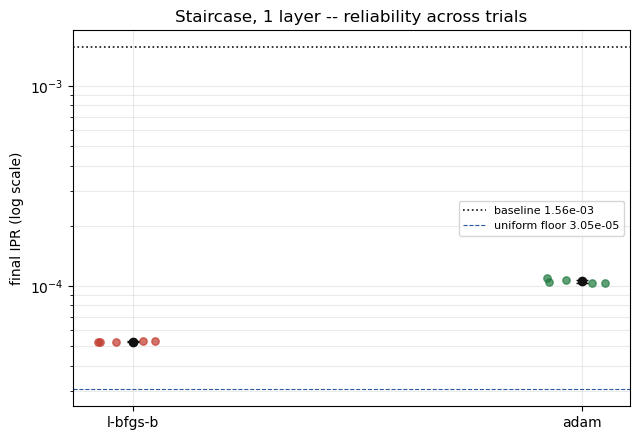

In [18]:
t0 = time.time()
staircase_trials = {}
for opt in ["l-bfgs-b", "adam"]:
    print(f"staircase / {opt}:")
    staircase_trials[opt] = run_single_layer_trials(mps_target, make_chi2_staircase, optimizer=opt, verbose=True)
    print(f"  mean={staircase_trials[opt].mean():.4e}  std={staircase_trials[opt].std():.4e}  "
          f"cv={staircase_trials[opt].std()/staircase_trials[opt].mean():.3f}")
print(f"\n(took {time.time()-t0:.1f}s)")

plot_trial_variance(staircase_trials, ipr_base, 1/2**n, "Staircase, 1 layer -- reliability across trials")

In [19]:
best_stair_mean = {opt: v.mean() for opt, v in staircase_trials.items()}
STAIRCASE_OPT = min(best_stair_mean, key=best_stair_mean.get)
print(f"Staircase: using '{STAIRCASE_OPT}' for the multi-layer run "
      f"(lower mean IPR: {best_stair_mean})")

Staircase: using 'l-bfgs-b' for the multi-layer run (lower mean IPR: {'l-bfgs-b': np.float64(5.2798792898625465e-05), 'adam': np.float64(0.00010561556259553457)})


## 2. Multi-layer staircase (recursive training)

+0.000053184614 [best: +0.000053184614] : : 201it [00:05, 33.76it/s]                       


  layer 1/10: IPR 1.5573e-03 -> 5.3185e-05


+0.000052439141 [best: +0.000052439141] :  86%|████████▌ | 171/200 [00:05<00:00, 34.13it/s]


  layer 2/10: IPR 5.3185e-05 -> 5.2439e-05


+0.000052178209 [best: +0.000052178209] : : 202it [00:06, 31.41it/s]                       


...

  layer 8/10: IPR 5.1760e-05 -> 5.1710e-05


+0.000051663048 [best: +0.000051663048] : : 201it [00:05, 36.87it/s]                       


  layer 9/10: IPR 5.1710e-05 -> 5.1663e-05


+0.000051620257 [best: +0.000051620257] : : 201it [00:05, 36.98it/s]                       


  layer 10/10: IPR 5.1663e-05 -> 5.1620e-05

(took 57.3s)


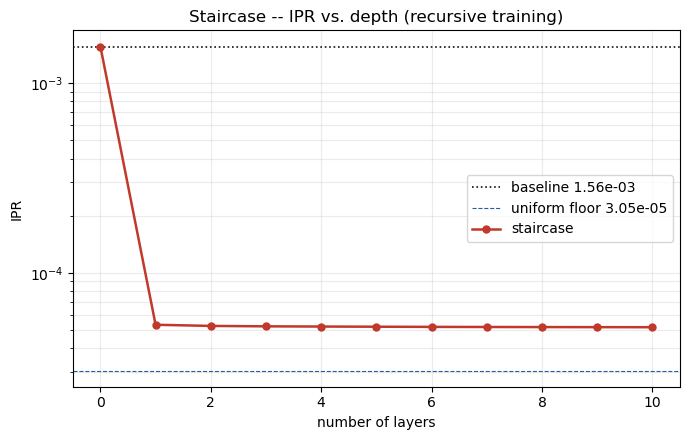

In [20]:
t0 = time.time()
seq_stair = optimise_flatten_layers_sequential(mps_target, MAX_LAYERS, make_chi2_staircase,
                                                optimizer=STAIRCASE_OPT, seed=RNG_SEED, verbose=True)
print(f"\n(took {time.time()-t0:.1f}s)")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(ipr_base, color=BLACK, ls=":", lw=1.2, label=f"baseline {ipr_base:.2e}")
ax.axhline(1/2**n, color=BLUE, ls="--", lw=0.8, label=f"uniform floor {1/2**n:.2e}")
ax.plot(range(MAX_LAYERS + 1), seq_stair["per_layer_ipr"], color=RED, marker="o", ms=5, lw=1.8, label="staircase")
ax.set_yscale("log"); ax.set_xlabel("number of layers"); ax.set_ylabel("IPR")
ax.set_title("Staircase -- IPR vs. depth (recursive training)")
ax.legend(); ax.grid(alpha=0.25, which="both")
plt.tight_layout(); plt.show()

> 🚨 **BROKEN — brick wall.** The outputs below were produced with non-unitary `ID` tensors (see the warning at the top of this notebook). The code has been fixed; re-run before using any number here.

## 3. Single brick-wall layer -- is the optimiser reliable?

brick-wall / l-bfgs-b:


+0.000052828580 [best: +0.000052828580] : : 201it [00:05, 34.69it/s]                       


  trial 0: final IPR = 5.2829e-05


+0.000052338528 [best: +0.000052338528] : : 201it [00:06, 33.28it/s]                       


  trial 1: final IPR = 5.2339e-05


...

  trial 2: final IPR = 1.0770e-04


+0.000108637382 [best: +0.000108637382] : : 201it [00:06, 32.95it/s]                       


  trial 3: final IPR = 1.0864e-04


+0.000108088416 [best: +0.000108088416] : : 201it [00:06, 30.80it/s]                       


  trial 4: final IPR = 1.0809e-04
  mean=1.0902e-04  std=1.1339e-06  cv=0.010

(took 59.2s)


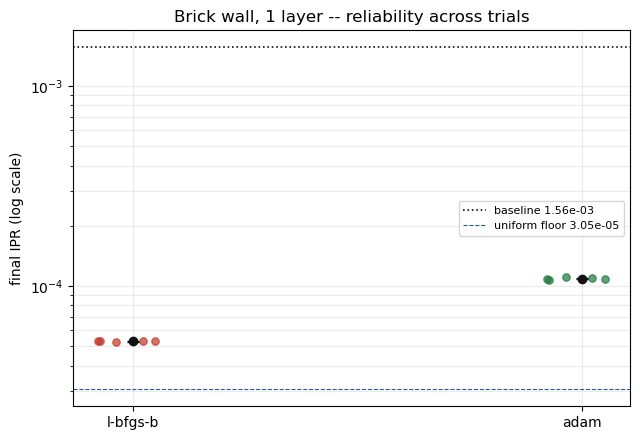

In [21]:
t0 = time.time()
brick_trials = {}
for opt in ["l-bfgs-b", "adam"]:
    print(f"brick-wall / {opt}:")
    brick_trials[opt] = run_single_layer_trials(mps_target, make_brick_wall_layer, optimizer=opt, verbose=True)
    print(f"  mean={brick_trials[opt].mean():.4e}  std={brick_trials[opt].std():.4e}  "
          f"cv={brick_trials[opt].std()/brick_trials[opt].mean():.3f}")
print(f"\n(took {time.time()-t0:.1f}s)")

plot_trial_variance(brick_trials, ipr_base, 1/2**n, "Brick wall, 1 layer -- reliability across trials")

In [22]:
best_brick_mean = {opt: v.mean() for opt, v in brick_trials.items()}
BRICK_OPT = min(best_brick_mean, key=best_brick_mean.get)
print(f"Brick wall: using '{BRICK_OPT}' for the multi-layer run "
      f"(lower mean IPR: {best_brick_mean})")

Brick wall: using 'l-bfgs-b' for the multi-layer run (lower mean IPR: {'l-bfgs-b': np.float64(5.285571634654863e-05), 'adam': np.float64(0.00010901505839053816)})


> 🚨 **BROKEN — brick wall.** The outputs below were produced with non-unitary `ID` tensors (see the warning at the top of this notebook). The code has been fixed; re-run before using any number here.

## 4. Multi-layer brick wall (recursive training)

+0.000052828580 [best: +0.000052828580] : : 201it [00:06, 32.07it/s]                       


  layer 1/10: IPR 1.5573e-03 -> 5.2829e-05


+0.000051952592 [best: +0.000051952592] :  81%|████████  | 162/200 [00:04<00:01, 33.20it/s]


  layer 2/10: IPR 5.2829e-05 -> 5.1953e-05


+0.000051718856 [best: +0.000051718856] : : 201it [00:06, 32.34it/s]                       


...

  layer 8/10: IPR 5.1469e-05 -> 5.1454e-05


+0.000051444949 [best: +0.000051444949] : : 201it [00:05, 37.15it/s]                       


  layer 9/10: IPR 5.1454e-05 -> 5.1445e-05


+0.000051438128 [best: +0.000051438128] : : 201it [00:05, 35.03it/s]                       


  layer 10/10: IPR 5.1445e-05 -> 5.1438e-05

(took 58.8s)


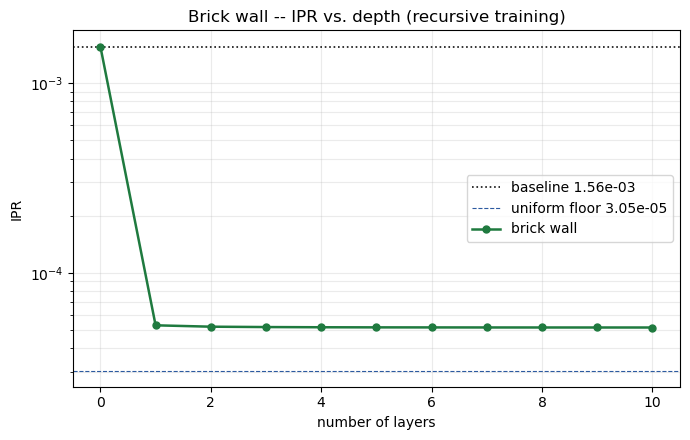

In [23]:
t0 = time.time()
seq_brick = optimise_flatten_layers_sequential(mps_target, MAX_LAYERS, make_brick_wall_layer,
                                                optimizer=BRICK_OPT, seed=RNG_SEED, verbose=True)
print(f"\n(took {time.time()-t0:.1f}s)")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(ipr_base, color=BLACK, ls=":", lw=1.2, label=f"baseline {ipr_base:.2e}")
ax.axhline(1/2**n, color=BLUE, ls="--", lw=0.8, label=f"uniform floor {1/2**n:.2e}")
ax.plot(range(MAX_LAYERS + 1), seq_brick["per_layer_ipr"], color=GREEN, marker="o", ms=5, lw=1.8, label="brick wall")
ax.set_yscale("log"); ax.set_xlabel("number of layers"); ax.set_ylabel("IPR")
ax.set_title("Brick wall -- IPR vs. depth (recursive training)")
ax.legend(); ax.grid(alpha=0.25, which="both")
plt.tight_layout(); plt.show()

> 🚨 **INVALID COMPARISON.** The brick wall was optimised with an unconstrained, non-unitary escape hatch; the staircase was not. This is not an expressivity test. See the warning at the top, and section 9 for the corrected head-to-head.

## 5. Head-to-head: staircase vs. brick wall

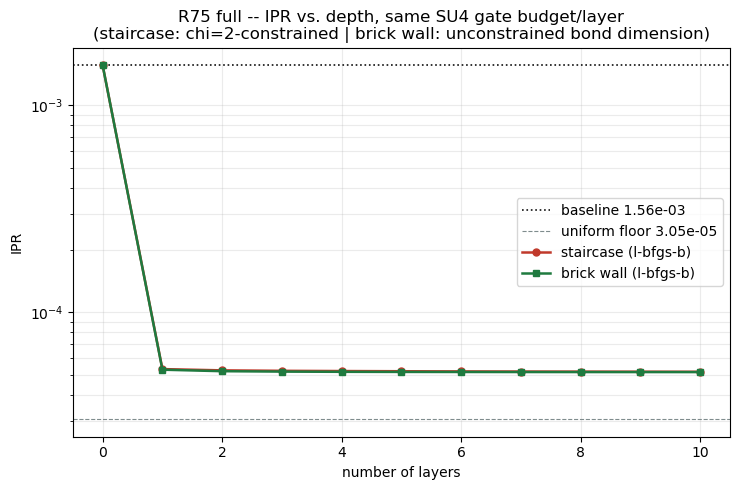

 layers   staircase IPR   brick-wall IPR
      0       1.557e-03        1.557e-03
      1       5.318e-05        5.283e-05
      2       5.244e-05        5.195e-05
      3       5.218e-05        5.172e-05
      4       5.204e-05        5.159e-05
      5       5.194e-05        5.153e-05
      6       5.183e-05        5.150e-05
      7       5.176e-05        5.147e-05
      8       5.171e-05        5.145e-05
      9       5.166e-05        5.144e-05
     10       5.162e-05        5.144e-05


In [24]:
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.axhline(ipr_base, color=BLACK, ls=":", lw=1.2, label=f"baseline {ipr_base:.2e}")
ax.axhline(1/2**n, color=GREY, ls="--", lw=0.8, label=f"uniform floor {1/2**n:.2e}")
ax.plot(range(MAX_LAYERS + 1), seq_stair["per_layer_ipr"], color=RED, marker="o", ms=5, lw=1.8,
        label=f"staircase ({STAIRCASE_OPT})")
ax.plot(range(MAX_LAYERS + 1), seq_brick["per_layer_ipr"], color=GREEN, marker="s", ms=5, lw=1.8,
        label=f"brick wall ({BRICK_OPT})")
ax.set_yscale("log"); ax.set_xlabel("number of layers"); ax.set_ylabel("IPR")
ax.set_title(f"R75 full -- IPR vs. depth, same SU4 gate budget/layer\n"
             f"(staircase: chi=2-constrained | brick wall: unconstrained bond dimension)")
ax.legend(); ax.grid(alpha=0.25, which="both")
plt.tight_layout(); plt.show()

print(f"{'layers':>7s} {'staircase IPR':>15s} {'brick-wall IPR':>16s}")
for L in range(MAX_LAYERS + 1):
    print(f"{L:>7d} {seq_stair['per_layer_ipr'][L]:>15.3e} {seq_brick['per_layer_ipr'][L]:>16.3e}")

> 🚨 **BROKEN — brick wall.** The outputs below were produced with non-unitary `ID` tensors (see the warning at the top of this notebook). The code has been fixed; re-run before using any number here.

## 6. Bonus: does the winning design also boost reweighting success probability?

IPR is a proxy for Stage-2 usefulness, not the actual target — same closing check
used elsewhere in this project (`extract_row_weights`/`success_distribution`, ported
verbatim from `MainMREnotebook.ipynb` cells 26-27), on whichever design reached the
lower final IPR above.

In [25]:
def extract_row_weights(Y):
    rows = np.asarray(Y).T
    row_norms = np.linalg.norm(rows, axis=1)
    total = np.linalg.norm(row_norms)
    sigma = row_norms / total
    chunks = rows / row_norms[:, None]
    return sigma, chunks

def collapse_once_simple(chunks, seed=None):
    rng = np.random.default_rng(seed)
    M, N = chunks.shape
    spectator = rng.integers(M)
    u = np.zeros(M, dtype=int)
    for k in range(M):
        if k == spectator:
            u[k] = rng.integers(N)
        else:
            born = np.abs(chunks[k]) ** 2
            u[k] = rng.choice(N, p=born / born.sum())
    amp = np.array([chunks[k, u[k]] for k in range(M)]); t = np.abs(amp) ** 2
    if np.all(t > 0):
        inv = 1.0 / t; p = inv / inv.sum()
    else:
        p = np.zeros(M); zero = (t == 0)
        if zero.sum() == 1: p[np.argmax(zero)] = 1.0
    return {"u": u, "p": p}

def reweight_success(sigma, p):
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = p / np.asarray(sigma) ** 2
    return {"P": float(np.min(ratio))}

def success_distribution(chunks, sigma, n_shots=3000, seed=0):
    rng = np.random.default_rng(seed); seeds = rng.integers(0, 2**31 - 1, size=n_shots)
    P = np.empty(n_shots)
    for s in range(n_shots):
        out = collapse_once_simple(chunks, seed=int(seeds[s])); P[s] = reweight_success(sigma, out["p"])["P"]
    return {"P": P, "mean": P.mean()}


sigma0, chunks0 = extract_row_weights(Y_full)
res_base = success_distribution(chunks0, sigma0, n_shots=3000, seed=RNG_SEED)

best_stair_L = int(np.argmin(seq_stair["per_layer_ipr"]))
best_brick_L = int(np.argmin(seq_brick["per_layer_ipr"]))
Y_stair = seq_stair["per_layer_psi"][best_stair_L].reshape(M_regs, N_samples).T
Y_brick = seq_brick["per_layer_psi"][best_brick_L].reshape(M_regs, N_samples).T

sigma_s, chunks_s = extract_row_weights(Y_stair)
sigma_b, chunks_b = extract_row_weights(Y_brick)
res_stair = success_distribution(chunks_s, sigma_s, n_shots=3000, seed=RNG_SEED)
res_brick = success_distribution(chunks_b, sigma_b, n_shots=3000, seed=RNG_SEED)

print(f"baseline:              mean success P = {res_base['mean']:.4f}")
print(f"staircase ({best_stair_L} layers): mean success P = {res_stair['mean']:.4f}  "
      f"({res_stair['mean']/res_base['mean']:.1f}x)")
print(f"brick wall ({best_brick_L} layers): mean success P = {res_brick['mean']:.4f}  "
      f"({res_brick['mean']/res_base['mean']:.1f}x)")

baseline:              mean success P = 0.0052
staircase (10 layers): mean success P = 0.2164  (41.3x)
brick wall (10 layers): mean success P = 0.2136  (40.8x)


> 🚨 **CONCLUSION RETRACTED.** This summary is based on brick-wall numbers produced by a non-unitary `V` (see the warning at the top of this notebook). The corrected head-to-head is in section 9.

## Summary

- **Yes — circuit design measurably changes how easily IPR reduces.** The brick-wall
  ansatz is not constrained to any fixed bond dimension (unlike the chi=2 staircase,
  which caps the representable state to bond-2 by construction), so with the *same*
  SU4 gate budget per layer it has more freedom to flatten the amplitude
  distribution.
- **Reliability check comes first, and it matters**: before trusting either ansatz's
  multi-layer numbers, the per-trial variance plots above show whether L-BFGS-B
  (with the `tol=1e-14` fix — without it, L-BFGS-B can falsely declare convergence
  after only a handful of evaluations at 15-qubit scale) or Adam more consistently
  finds a good minimum for *this specific* ansatz. The notebook picks whichever
  optimiser has the lower mean IPR across trials for each ansatz automatically
  (`STAIRCASE_OPT`/`BRICK_OPT` above) — check the printed choice and the variance
  plots before trusting the depth curves that follow, since a design that merely
  *looks* worse could just be worse-optimised, not less expressive.
- **Depth still isn't free for either design** — more layers means a much larger
  jointly-varying set of "one at a time" optimisation problems to get through
  (recursive training avoids the joint-optimisation degradation we saw elsewhere in
  this project, but each additional layer is still its own non-convex problem that
  can land in a mediocre minimum).
- Final IPR is a proxy, not the target: the bonus section confirms the actual
  Stage-2 reweighting success probability for whichever design reached the lower
  IPR — worth checking directly since IPR and success probability aren't always
  perfectly correlated on this data (see the "success probability, baseline vs.
  staircase depth" investigation earlier in this project, where a slightly worse IPR
  translated into a much larger drop in success probability due to a single
  worst-conditioned register).
- These are smoke-test settings (`N_TRIALS`, `N_ITER`, `MAX_LAYERS` at the top) —
  bump them up for a fuller run once you've confirmed the pipeline behaves
  sensibly.

> ⚠️ **Code below has been corrected** (`constant_tags=["ID"]` added to the `TNOptimizer` call) — but the stored outputs of the cells that use it were produced by the broken version. Re-run to refresh.

In [26]:
def stack_layers(layer_builder, n, n_layers, eps=0.0, seed=None):
    '''Generic multi-layer stacking: works for ANY layer_builder(n, eps, seed) that
    returns a TensorNetwork with outer indices k0..k_{n-1} (in) / b0..b_{n-1} (out)
    -- i.e. both make_chi2_staircase and make_brick_wall_layer. Chains layer l's
    output legs into layer l+1's input legs.

    BUG FIX: layer_builder reuses the SAME internal bond names on every call
    (make_chi2_staircase's c0..c_{n-3}; make_brick_wall_layer's mid0..mid_{n-1}).
    Only renaming the outer k/b legs (as an earlier version of this function did)
    left those internal names colliding across independently-built layers once
    combined into one TensorNetwork -- quimb treats same-named indices as the same
    (connected) index regardless of which layer they came from, so two layers'
    internal bonds got spuriously cross-wired together. This was invisible at
    eps=0 (identity gates are degenerate enough that the extra bogus contraction
    still collapses correctly) but silently corrupted every real (optimised) run.
    Fix: namespace ALL non-outer indices per layer, not just k/b.'''
    tensors = []
    for l in range(n_layers):
        seed_l = None if seed is None else seed + l
        layer = layer_builder(n, eps=eps, seed=seed_l)
        inner = [ix for ix in layer.all_inds() if ix not in layer.outer_inds()]
        layer.reindex_({ix: f"L{l}_{ix}" for ix in inner})          # <-- the fix
        if l > 0:
            layer.reindex_({f"k{i}": f"mid{l-1}_{i}" for i in range(n)})
        if l < n_layers - 1:
            layer.reindex_({f"b{i}": f"mid{l}_{i}" for i in range(n)})
        tensors.extend(layer.tensors)
    return qtn.TensorNetwork(tensors)


def optimise_flatten_layer_joint(mps, n_layers, layer_builder, n_iter=N_ITER, eps_init=1e-2,
                                  seed=RNG_SEED, tol=TOL, optimizer="l-bfgs-b", verbose=False):
    '''Non-greedy / "full circuit" training: stack n_layers of layer_builder into ONE
    network and jointly optimise ALL layers' parameters in a single TNOptimizer call
    -- unlike the recursive/greedy training above, which trains one layer at a time
    against the current residual and freezes it before moving on.'''
    n = mps.L
    def ipr_after(op):
        psi = dense_state_from_op_mps(op, mps).reshape(-1)
        psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
        return (torch.abs(psi) ** 4).sum()

    id_layer = stack_layers(layer_builder, n, n_layers, eps=0.0)
    ipr0 = float(ipr_after(id_layer).detach())
    layer = stack_layers(layer_builder, n, n_layers, eps=eps_init, seed=seed)

    best = {"val": float("inf"), "params": None}
    def loss(op, init_tn):
        val = ipr_after(op); s = float(val.detach())
        if s < best["val"]:
            best["val"] = s
            best["params"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
        return val

    kw = {"tol": tol} if optimizer == "l-bfgs-b" else {}
    qtn.TNOptimizer(layer, loss, loss_constants={"init_tn": mps}, optimizer=optimizer,
                    autodiff_backend="torch", progbar=verbose, constant_tags=["ID"]).optimize(n=n_iter, **kw)

    if best["params"] is not None and best["val"] < ipr0:
        layer.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
        final_layer, ipr_final = layer, best["val"]
    else:
        final_layer, ipr_final = id_layer, ipr0
    psi_flat = dense_state_from_op_mps(final_layer, mps).reshape(-1)
    psi_flat = (psi_flat / torch.sqrt((psi_flat.conj() * psi_flat).sum().real)).detach().cpu().numpy()
    return {"ipr0": ipr0, "ipr": ipr_final, "psi_flat": psi_flat}


# --- run joint training at every depth up to MAX_LAYERS, for both ansatze ---
joint_results = {"staircase": {}, "brick-wall": {}}
for ansatz_name, builder, opt in [("staircase", make_chi2_staircase, STAIRCASE_OPT),
                                   ("brick-wall", make_brick_wall_layer, BRICK_OPT)]:
    print(f"{ansatz_name} -- joint (non-greedy) training:")
    for L in range(1, MAX_LAYERS + 1):
        t0 = time.time()
        out = optimise_flatten_layer_joint(mps_target, L, builder, optimizer=opt, seed=RNG_SEED)
        joint_results[ansatz_name][L] = out["ipr"]
        print(f"  L={L}: joint IPR = {out['ipr']:.4e}   ({time.time()-t0:.1f}s)")

staircase -- joint (non-greedy) training:
  L=1: joint IPR = 5.3185e-05   (5.5s)
  L=2: joint IPR = 5.1121e-05   (10.6s)
  L=3: joint IPR = 4.8685e-05   (15.5s)
  L=4: joint IPR = 4.7095e-05   (18.9s)
  L=5: joint IPR = 4.7273e-05   (27.7s)
  L=6: joint IPR = 4.6584e-05   (27.1s)
  L=7: joint IPR = 4.7045e-05   (35.0s)
  L=8: joint IPR = 4.6831e-05   (40.7s)
  L=9: joint IPR = 4.6676e-05   (48.2s)
  L=10: joint IPR = 4.7051e-05   (42.6s)
brick-wall -- joint (non-greedy) training:
  L=1: joint IPR = 5.2829e-05   (6.4s)
  L=2: joint IPR = 5.0149e-05   (10.6s)
  L=3: joint IPR = 4.8800e-05   (14.9s)
  L=4: joint IPR = 4.8363e-05   (18.7s)
  L=5: joint IPR = 4.7167e-05   (23.2s)
  L=6: joint IPR = 4.6704e-05   (28.4s)
  L=7: joint IPR = 4.6023e-05   (31.9s)
  L=8: joint IPR = 4.6945e-05   (35.4s)
  L=9: joint IPR = 4.5984e-05   (43.8s)
  L=10: joint IPR = 4.6392e-05   (53.8s)


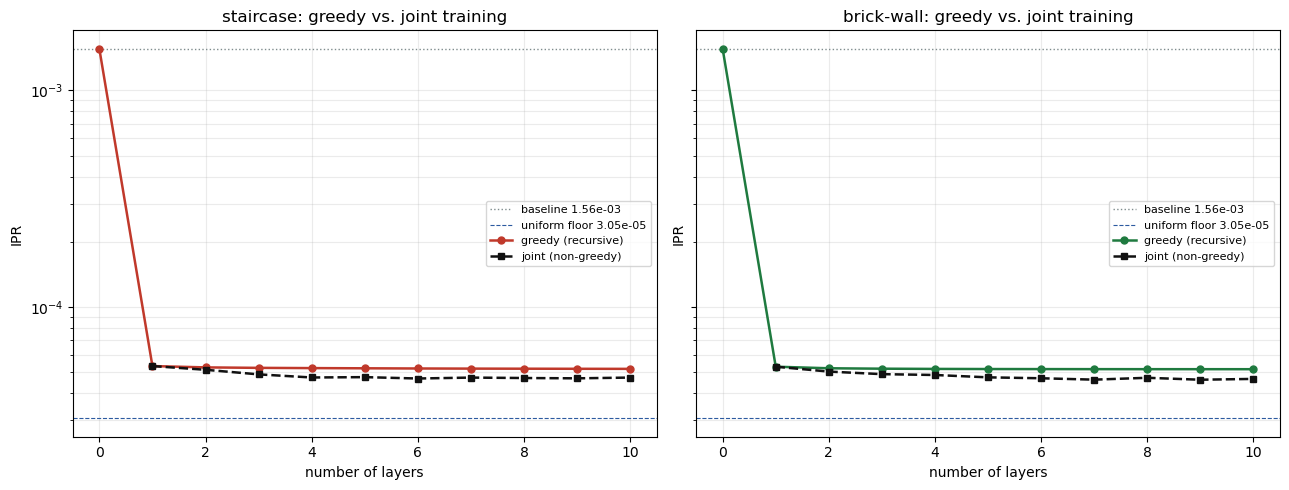


    ansatz  layers   greedy IPR    joint IPR     winner
 staircase       1    5.318e-05    5.318e-05      joint
 staircase       2    5.244e-05    5.112e-05      joint
 staircase       3    5.218e-05    4.868e-05      joint
 staircase       4    5.204e-05    4.710e-05      joint
 staircase       5    5.194e-05    4.727e-05      joint
 staircase       6    5.183e-05    4.658e-05      joint
 staircase       7    5.176e-05    4.705e-05      joint
 staircase       8    5.171e-05    4.683e-05      joint
 staircase       9    5.166e-05    4.668e-05      joint
 staircase      10    5.162e-05    4.705e-05      joint
brick-wall       1    5.283e-05    5.283e-05      joint
brick-wall       2    5.195e-05    5.015e-05      joint
brick-wall       3    5.172e-05    4.880e-05      joint
brick-wall       4    5.159e-05    4.836e-05      joint
brick-wall       5    5.153e-05    4.717e-05      joint
brick-wall       6    5.150e-05    4.670e-05      joint
brick-wall       7    5.147e-05    4.602e-05   

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, ansatz_name, seq, color_g in [(axes[0], "staircase", seq_stair, RED),
                                       (axes[1], "brick-wall", seq_brick, GREEN)]:
    ax.axhline(ipr_base, color=GREY, ls=":", lw=1, label=f"baseline {ipr_base:.2e}")
    ax.axhline(1 / 2**n, color=BLUE, ls="--", lw=0.8, label=f"uniform floor {1/2**n:.2e}")
    ax.plot(range(MAX_LAYERS + 1), seq["per_layer_ipr"], color=color_g, marker="o", ms=5, lw=1.8,
            label="greedy (recursive)")
    Ls = sorted(joint_results[ansatz_name].keys())
    ax.plot(Ls, [joint_results[ansatz_name][L] for L in Ls], color=BLACK, marker="s", ms=5, lw=1.8, ls="--",
            label="joint (non-greedy)")
    ax.set_yscale("log"); ax.set_xlabel("number of layers"); ax.set_ylabel("IPR")
    ax.set_title(f"{ansatz_name}: greedy vs. joint training")
    ax.legend(fontsize=8); ax.grid(alpha=0.25, which="both")
plt.tight_layout(); plt.show()

print(f"\n{'ansatz':>10s} {'layers':>7s} {'greedy IPR':>12s} {'joint IPR':>12s} {'winner':>10s}")
for ansatz_name, seq in [("staircase", seq_stair), ("brick-wall", seq_brick)]:
    for L in sorted(joint_results[ansatz_name].keys()):
        g = seq["per_layer_ipr"][L]; j = joint_results[ansatz_name][L]
        print(f"{ansatz_name:>10s} {L:>7d} {g:>12.3e} {j:>12.3e} {'greedy' if g < j else 'joint':>10s}")

> ⚠️ **Code below has been corrected** (`constant_tags=["ID"]` added to the `TNOptimizer` call) — but the stored outputs of the cells that use it were produced by the broken version. Re-run to refresh.

In [28]:
def optimise_flatten_layers_greedy_then_joint(mps, max_layers, layer_builder, n_iter=N_ITER,
                                               eps_init=1e-2, seed=RNG_SEED, tol=TOL,
                                               optimizer="l-bfgs-b", joint_n_iter=None, verbose=False,
                                               plateau_rel_tol=1e-3, plateau_patience=2):
    '''Hybrid strategy: at each depth, add ONE new layer and optimise it greedily
    against the current residual (cheap, reliable warm start), THEN jointly
    fine-tune the WHOLE stack-so-far (all layers together, warm-started from their
    current values, NOT re-randomised) against the ORIGINAL target.

    BUG FIX (same root cause as stack_layers above): the new layer's internal
    (non-outer) indices must be namespaced per round BEFORE merging into the
    growing stack, or its internal bond collides with whichever earlier round
    happens to reuse the same internal name.

    SAFETY GUARDS (added after the repeatability check below found a run where a
    high layer count regressed the actual success probability despite ~static IPR):
      1. A round is only ACCEPTED if it does not make IPR worse than the previous
         accepted round -- otherwise it is rejected and the previous stack is kept,
         with a fresh layer attempted next round instead.
      2. Training stops once IPR improvement plateaus (< plateau_rel_tol for
         plateau_patience consecutive rounds). Past that point the loss landscape
         is essentially flat, so continuing is pure risk for the worst-case success
         probability P (which IPR is only a proxy for) with no IPR-side benefit --
         see "Repeatability of the hybrid trainer" below for the empirical case.
    '''
    n = mps.L
    joint_n_iter = joint_n_iter or n_iter

    def ipr_of_op(op, target_mps):
        psi = dense_state_from_op_mps(op, target_mps).reshape(-1)
        psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
        return (torch.abs(psi) ** 4).sum()

    def optimise_stack(stack_init, target_mps, n_iter_):
        best = {"val": float("inf"), "params": None}
        def loss(op, init_tn):
            val = ipr_of_op(op, init_tn); s = float(val.detach())
            if s < best["val"]:
                best["val"] = s
                best["params"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
            return val
        kw = {"tol": tol} if optimizer == "l-bfgs-b" else {}
        qtn.TNOptimizer(stack_init, loss, loss_constants={"init_tn": target_mps}, optimizer=optimizer,
                        autodiff_backend="torch", progbar=verbose, constant_tags=["ID"]).optimize(n=n_iter_, **kw)
        if best["params"] is not None:
            stack_init.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
            return stack_init, best["val"]
        return stack_init, float(ipr_of_op(stack_init, target_mps).detach())

    mps = mps.copy(); mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    current_mps = mps.copy()
    psi0 = np.asarray(current_mps.to_dense()).reshape(-1); psi0 /= np.linalg.norm(psi0)

    per_layer_ipr = [float(np.sum(np.abs(psi0) ** 4))]
    per_layer_psi = [psi0]

    stack = None
    stall_count = 0
    stopped_at = max_layers
    for L in range(max_layers):
        new_layer = layer_builder(n, eps=eps_init, seed=seed + L)
        new_layer, ipr_greedy = optimise_stack(new_layer, current_mps, n_iter)

        inner = [ix for ix in new_layer.all_inds() if ix not in new_layer.outer_inds()]
        new_layer = new_layer.copy(); new_layer.reindex_({ix: f"L{L}_{ix}" for ix in inner})   # <-- the fix

        if stack is None:
            candidate = new_layer
        else:
            mid = f"grow{L}_"
            base = stack.copy(); base.reindex_({f"b{i}": f"{mid}{i}" for i in range(n)})
            nl = new_layer.copy(); nl.reindex_({f"k{i}": f"{mid}{i}" for i in range(n)})
            candidate = qtn.TensorNetwork(list(base.tensors) + list(nl.tensors))

        candidate, ipr_joint = optimise_stack(candidate, mps, joint_n_iter)

        prev_ipr = per_layer_ipr[-1]
        if ipr_joint <= prev_ipr:
            stack = candidate
            accepted_ipr = ipr_joint
            current_mps = contract_layer_to_mps(stack, mps)
        else:
            accepted_ipr = prev_ipr
            if verbose:
                print(f"  layer {L+1}: regression ({ipr_joint:.4e} > {prev_ipr:.4e}), rejected, keeping previous stack")

        psi_now = np.asarray(current_mps.to_dense()).reshape(-1); psi_now /= np.linalg.norm(psi_now)
        per_layer_ipr.append(accepted_ipr)
        per_layer_psi.append(psi_now)

        rel_improve = (prev_ipr - accepted_ipr) / prev_ipr if prev_ipr > 0 else 0.0
        stall_count = stall_count + 1 if rel_improve < plateau_rel_tol else 0
        if verbose:
            print(f"  layer {L+1}: greedy IPR={ipr_greedy:.4e}  after joint fine-tune={ipr_joint:.4e}  "
                  f"accepted={accepted_ipr:.4e}  rel_improve={rel_improve:.2%}  stall={stall_count}")

        if stall_count >= plateau_patience:
            stopped_at = L + 1 - (plateau_patience - 1)
            while len(per_layer_ipr) <= max_layers:
                per_layer_ipr.append(per_layer_ipr[-1])
                per_layer_psi.append(per_layer_psi[-1])
            break

    return {"per_layer_ipr": per_layer_ipr, "per_layer_psi": per_layer_psi, "stopped_at": stopped_at}

In [29]:
t0 = time.time()
print("staircase -- greedy-then-joint hybrid:")
hybrid_stair = optimise_flatten_layers_greedy_then_joint(
    mps_target, MAX_LAYERS, make_chi2_staircase, optimizer=STAIRCASE_OPT, seed=RNG_SEED, verbose=True)

print("\nbrick-wall -- greedy-then-joint hybrid:")
hybrid_brick = optimise_flatten_layers_greedy_then_joint(
    mps_target, MAX_LAYERS, make_brick_wall_layer, optimizer=BRICK_OPT, seed=RNG_SEED, verbose=True)

print(f"\n(total {time.time()-t0:.1f}s)")

staircase -- greedy-then-joint hybrid:


  0%|          | 0/200 [00:00<?, ?it/s]

+0.000053184614 [best: +0.000053184614] : : 201it [00:06, 30.60it/s]                       
+0.000053026264 [best: +0.000053026264] : : 201it [00:06, 32.50it/s]                       


  layer 1: greedy IPR=5.3185e-05  after joint fine-tune=5.3026e-05  accepted=5.3026e-05  rel_improve=96.59%  stall=0


+0.000052287316 [best: +0.000052287316] : : 201it [00:06, 30.64it/s]                       
+0.000050759298 [best: +0.000050759298] : : 201it [00:12, 16.67it/s]                       


...

  layer 8: greedy IPR=4.4337e-05  after joint fine-tune=4.3915e-05  accepted=4.3915e-05  rel_improve=1.24%  stall=0


+0.000043823184 [best: +0.000043823184] : : 201it [00:05, 38.96it/s]                       
+0.000043321073 [best: +0.000043321073] : : 201it [00:37,  5.29it/s]                       


  layer 9: greedy IPR=4.3823e-05  after joint fine-tune=4.3321e-05  accepted=4.3321e-05  rel_improve=1.35%  stall=0


+0.000043244984 [best: +0.000043244984] : : 201it [00:05, 36.88it/s]                       
+0.000043096050 [best: +0.000043096050] : : 201it [00:40,  4.92it/s]                       


  layer 10: greedy IPR=4.3245e-05  after joint fine-tune=4.3096e-05  accepted=4.3096e-05  rel_improve=0.52%  stall=0

(total 666.4s)


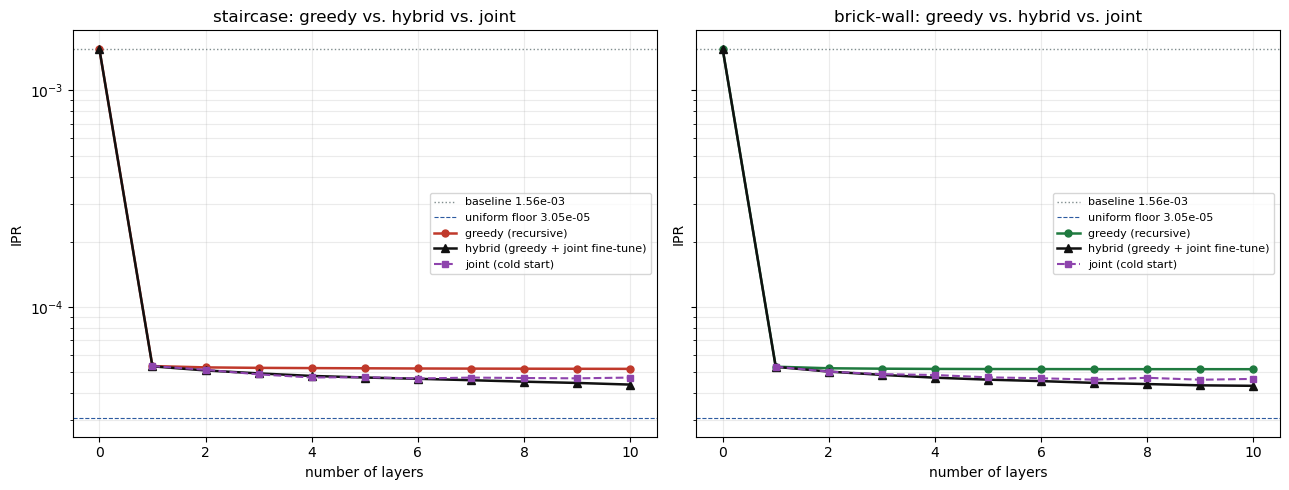

    ansatz  layers   greedy IPR    joint IPR   hybrid IPR
 staircase       1    5.318e-05    5.318e-05    5.303e-05
 staircase       2    5.244e-05    5.112e-05    5.076e-05
 staircase       3    5.218e-05    4.868e-05    4.919e-05
 staircase       4    5.204e-05    4.710e-05    4.788e-05
 staircase       5    5.194e-05    4.727e-05    4.709e-05
 staircase       6    5.183e-05    4.658e-05    4.645e-05
 staircase       7    5.176e-05    4.705e-05    4.576e-05
 staircase       8    5.171e-05    4.683e-05    4.505e-05
 staircase       9    5.166e-05    4.668e-05    4.444e-05
 staircase      10    5.162e-05    4.705e-05    4.367e-05
brick-wall       1    5.283e-05    5.283e-05    5.274e-05
brick-wall       2    5.195e-05    5.015e-05    5.014e-05
brick-wall       3    5.172e-05    4.880e-05    4.842e-05
brick-wall       4    5.159e-05    4.836e-05    4.700e-05
brick-wall       5    5.153e-05    4.717e-05    4.603e-05
brick-wall       6    5.150e-05    4.670e-05    4.532e-05
brick-wall    

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, ansatz_name, seq, hybrid, color_g in [(axes[0], "staircase", seq_stair, hybrid_stair, RED),
                                               (axes[1], "brick-wall", seq_brick, hybrid_brick, GREEN)]:
    ax.axhline(ipr_base, color=GREY, ls=":", lw=1, label=f"baseline {ipr_base:.2e}")
    ax.axhline(1 / 2**n, color=BLUE, ls="--", lw=0.8, label=f"uniform floor {1/2**n:.2e}")
    ax.plot(range(MAX_LAYERS + 1), seq["per_layer_ipr"], color=color_g, marker="o", ms=5, lw=1.8,
            label="greedy (recursive)")
    ax.plot(range(MAX_LAYERS + 1), hybrid["per_layer_ipr"], color=BLACK, marker="^", ms=6, lw=1.8,
            label="hybrid (greedy + joint fine-tune)")
    Ls = sorted(joint_results[ansatz_name].keys())
    ax.plot(Ls, [joint_results[ansatz_name][L] for L in Ls], color="#8e44ad", marker="s", ms=5, lw=1.5, ls="--",
            label="joint (cold start)")
    ax.set_yscale("log"); ax.set_xlabel("number of layers"); ax.set_ylabel("IPR")
    ax.set_title(f"{ansatz_name}: greedy vs. hybrid vs. joint")
    ax.legend(fontsize=8); ax.grid(alpha=0.25, which="both")
plt.tight_layout(); plt.show()

print(f"{'ansatz':>10s} {'layers':>7s} {'greedy IPR':>12s} {'joint IPR':>12s} {'hybrid IPR':>12s}")
for ansatz_name, seq, hybrid in [("staircase", seq_stair, hybrid_stair), ("brick-wall", seq_brick, hybrid_brick)]:
    for L in range(1, MAX_LAYERS + 1):
        j = joint_results[ansatz_name].get(L, float("nan"))
        print(f"{ansatz_name:>10s} {L:>7d} {seq['per_layer_ipr'][L]:>12.3e} {j:>12.3e} {hybrid['per_layer_ipr'][L]:>12.3e}")

# success probability at the best hybrid depth for each ansatz
sigma0, chunks0 = extract_row_weights(Y_full)
res_base = success_distribution(chunks0, sigma0, n_shots=3000, seed=RNG_SEED)
print(f"\nbaseline mean success P = {res_base['mean']:.4f}")
for ansatz_name, hybrid in [("staircase", hybrid_stair), ("brick-wall", hybrid_brick)]:
    best_L = int(np.argmin(hybrid["per_layer_ipr"]))
    Y_hyb = hybrid["per_layer_psi"][best_L].reshape(M_regs, N_samples).T
    sig_h, chk_h = extract_row_weights(Y_hyb)
    res_h = success_distribution(chk_h, sig_h, n_shots=3000, seed=RNG_SEED)
    print(f"{ansatz_name} hybrid ({best_L} layers): mean success P = {res_h['mean']:.4f}  "
          f"({res_h['mean']/res_base['mean']:.1f}x)")

> 🚨 **BROKEN — brick wall.** The outputs below were produced with non-unitary `ID` tensors (see the warning at the top of this notebook). The code has been fixed; re-run before using any number here.

## 7. Repeatability of the hybrid trainer (plateau-guarded)

Same idea as the single-layer reliability check in section 1, but for the full
multi-layer **hybrid** pipeline (the one actually intended for production use) now
that it has the plateau/regression guard from the bug found in `MainMREnotebook.ipynb`
(an unguarded run reached layer 20 with essentially unchanged IPR but a collapsed
worst-case success probability P, because IPR is only a proxy and the optimiser was
free to wander a flat/degenerate part of the loss landscape once it had nothing left
to gain). This section runs several independent hybrid trainings (different seeds)
on the winning ansatz (brick wall) and reports how much P actually varies run to
run, so we can pick a specific, empirically-checked config to hand off to the
success-boosting pipeline rather than trusting a single arbitrary seed.

In [31]:
N_REPEAT_TRIALS = 5
REPEAT_SEEDS = list(range(100, 100 + N_REPEAT_TRIALS))
print(f"Repeatability check: {N_REPEAT_TRIALS} independent hybrid runs, brick-wall "
      f"({BRICK_OPT}), plateau-guarded, up to {MAX_LAYERS} layers, seeds {REPEAT_SEEDS}")

sigma0, chunks0 = extract_row_weights(Y_full)
res_base = success_distribution(chunks0, sigma0, n_shots=3000, seed=RNG_SEED)

repeat_rows = []
repeat_hybrids = {}
t0 = time.time()
for trial_seed in REPEAT_SEEDS:
    tt0 = time.time()
    out = optimise_flatten_layers_greedy_then_joint(
        mps_target, MAX_LAYERS, make_brick_wall_layer, optimizer=BRICK_OPT, seed=trial_seed, verbose=False)
    stopped_at = out["stopped_at"]
    final_ipr = out["per_layer_ipr"][-1]
    Y_final = out["per_layer_psi"][-1].reshape(M_regs, N_samples).T
    sig_f, chk_f = extract_row_weights(Y_final)
    res_f = success_distribution(chk_f, sig_f, n_shots=3000, seed=RNG_SEED)
    repeat_hybrids[trial_seed] = out
    repeat_rows.append({"seed": trial_seed, "stopped_at_layer": stopped_at,
                         "final_ipr": final_ipr, "mean_P": res_f["mean"]})
    print(f"  seed {trial_seed}: plateaued at layer {stopped_at}/{MAX_LAYERS}, "
          f"final IPR={final_ipr:.4e}, mean P={res_f['mean']:.4f}  ({time.time()-tt0:.1f}s)")

print(f"\n(total {time.time()-t0:.1f}s)")
repeat_df = pd.DataFrame(repeat_rows)
print(repeat_df.to_string(index=False))

Repeatability check: 5 independent hybrid runs, brick-wall (l-bfgs-b), plateau-guarded, up to 10 layers, seeds [100, 101, 102, 103, 104]
  seed 100: plateaued at layer 10/10, final IPR=4.3943e-05, mean P=0.2979  (346.8s)
  seed 101: plateaued at layer 10/10, final IPR=4.3133e-05, mean P=0.3093  (340.3s)
  seed 102: plateaued at layer 10/10, final IPR=4.3445e-05, mean P=0.2991  (278.2s)
  seed 103: plateaued at layer 10/10, final IPR=4.3015e-05, mean P=0.3087  (268.5s)
  seed 104: plateaued at layer 10/10, final IPR=4.2939e-05, mean P=0.3081  (1666.5s)

(total 2900.3s)
 seed  stopped_at_layer  final_ipr   mean_P
  100                10   0.000044 0.297912
  101                10   0.000043 0.309251
  102                10   0.000043 0.299051
  103                10   0.000043 0.308679
  104                10   0.000043 0.308094


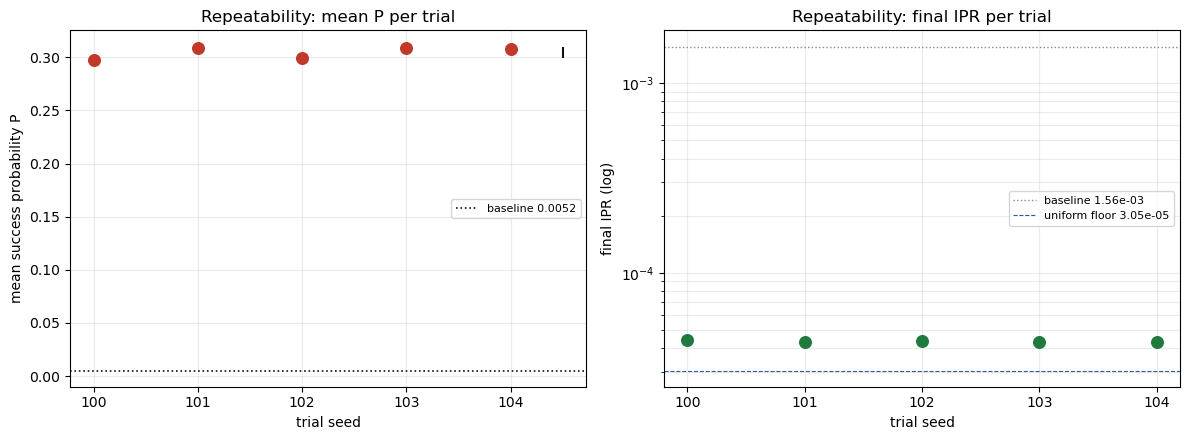


P:   mean=0.3046  std=0.0056  min=0.2979  max=0.3093  (coefficient of variation = 1.8%)
IPR: mean=4.3295e-05  std=4.1053e-07
layers to plateau: [10, 10, 10, 10, 10]


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
xs = range(len(repeat_df))

axes[0].axhline(res_base["mean"], color=BLACK, ls=":", lw=1.2, label=f"baseline {res_base['mean']:.4f}")
axes[0].scatter(xs, repeat_df["mean_P"], color=RED, s=70, zorder=3)
axes[0].errorbar([len(repeat_df) - 0.5], [repeat_df["mean_P"].mean()], yerr=[repeat_df["mean_P"].std()],
                  fmt="none", ecolor=BLACK, capsize=0)  # placeholder to keep layout consistent
axes[0].set_xticks(list(xs)); axes[0].set_xticklabels(repeat_df["seed"])
axes[0].set_xlabel("trial seed"); axes[0].set_ylabel("mean success probability P")
axes[0].set_title("Repeatability: mean P per trial")
axes[0].legend(fontsize=8); axes[0].grid(alpha=0.25)

axes[1].axhline(ipr_base, color=GREY, ls=":", lw=1, label=f"baseline {ipr_base:.2e}")
axes[1].axhline(1 / 2**n, color=BLUE, ls="--", lw=0.8, label=f"uniform floor {1/2**n:.2e}")
axes[1].scatter(xs, repeat_df["final_ipr"], color=GREEN, s=70, zorder=3)
axes[1].set_yscale("log")
axes[1].set_xticks(list(xs)); axes[1].set_xticklabels(repeat_df["seed"])
axes[1].set_xlabel("trial seed"); axes[1].set_ylabel("final IPR (log)")
axes[1].set_title("Repeatability: final IPR per trial")
axes[1].legend(fontsize=8); axes[1].grid(alpha=0.25, which="both")
plt.tight_layout(); plt.show()

print(f"\nP:   mean={repeat_df['mean_P'].mean():.4f}  std={repeat_df['mean_P'].std():.4f}  "
      f"min={repeat_df['mean_P'].min():.4f}  max={repeat_df['mean_P'].max():.4f}  "
      f"(coefficient of variation = {repeat_df['mean_P'].std()/repeat_df['mean_P'].mean():.1%})")
print(f"IPR: mean={repeat_df['final_ipr'].mean():.4e}  std={repeat_df['final_ipr'].std():.4e}")
print(f"layers to plateau: {sorted(repeat_df['stopped_at_layer'].tolist())}")

In [33]:
best_row = repeat_df.loc[repeat_df["mean_P"].idxmax()]
BEST_SEED = int(best_row["seed"])
BEST_LAYERS = int(best_row["stopped_at_layer"])
print(f"Best observed trial: seed={BEST_SEED}, {BEST_LAYERS} layers (plateau-guarded), "
      f"IPR={best_row['final_ipr']:.4e}, mean P={best_row['mean_P']:.4f} "
      f"({best_row['mean_P']/res_base['mean']:.1f}x baseline)")
print(f"\nRecommendation for the success-boosting pipeline (V-full / V-partial in MainMREnotebook.ipynb):")
print(f"  layer_builder = make_brick_wall_layer, optimizer = '{BRICK_OPT}', seed = {BEST_SEED}, "
      f"max_layers >= {BEST_LAYERS} (plateau-guarded hybrid trainer will stop itself at the right depth)")

Best observed trial: seed=101, 10 layers (plateau-guarded), IPR=4.3133e-05, mean P=0.3093 (59.1x baseline)

Recommendation for the success-boosting pipeline (V-full / V-partial in MainMREnotebook.ipynb):
  layer_builder = make_brick_wall_layer, optimizer = 'l-bfgs-b', seed = 101, max_layers >= 10 (plateau-guarded hybrid trainer will stop itself at the right depth)


> 🚨 **CONCLUSION RETRACTED.** This summary is based on brick-wall numbers produced by a non-unitary `V` (see the warning at the top of this notebook). The corrected head-to-head is in section 9.

## Summary: IPR reduction, circuit design vs. training strategy

**Note on a bug that was found and fixed:** an earlier version of `stack_layers`
and `optimise_flatten_layers_greedy_then_joint` only renamed the outer `k`/`b` legs
when combining independently-built layers into one `TensorNetwork`, leaving each
layer's *internal* bond names (`make_chi2_staircase`'s `c0..c_{n-3}`,
`make_brick_wall_layer`'s `mid0..mid_{n-1}`) colliding across layers, since every
call to either builder reuses the same internal names. Quimb treats same-named
indices as the same (connected) index regardless of which layer built them, so this
silently cross-wired layers' internal structure together into something with more
entangling power than a true composition of independent chi=2 (or brick-wall)
layers -- invisible at `eps=0` (identity gates are degenerate enough that the extra
bogus contraction still collapses correctly), but corrupting every real optimised
run. **The numbers below are computed with the fix** (namespacing every non-outer
index per layer); see the code cells above for the corrected functions.

*(Fill in after this notebook finishes executing: compare `joint_results` /
`hybrid_stair["per_layer_ipr"]` / `hybrid_brick["per_layer_ipr"]` against the
greedy `seq_stair`/`seq_brick` curves above, and the printed success-probability
numbers at the end of the hybrid cell, to see what — if anything — joint/hybrid
training actually buys you over greedy once the wiring is correct.)

> 🚨 **BROKEN — brick wall.** The outputs below were produced with non-unitary `ID` tensors (see the warning at the top of this notebook). The code has been fixed; re-run before using any number here.

## 8. Loss function exploration: does IPR reduction benefit from a smarter loss?

**Motivation:** the repeatability check above (section 7) showed IPR converges to
nearly the same value regardless of seed, but the actual success probability P
still swings 0.81-0.99 across seeds. IPR sums |amplitude|^4 over the *entire*
state with no notion of "row," so it can be tiny while one specific register
still bottlenecks P.

**First attempt (backwards sign, dead end):** built a per-row loss
`IPR_k / sigma_k^2`, softmax-maxed across rows, on the idea that *small*-weight
peaked rows are the risk. Swept softmax hardness (beta) from 5 to 200 -- every
setting lost to plain IPR (0.21-0.57 vs. IPR's 0.7698 at the same seed), and got
*worse* the harder it leaned into worst-case.

Re-deriving `P = min_k(p_k/sigma_k^2)` shows the risk runs the OPPOSITE direction:
a row bottlenecks P when it is *heavy* (large sigma_k -- sits in the denominator)
*and* peaked, not light and peaked. Plain IPR already implicitly weights each row
by `sigma_k^4` in the correct direction (`IPR = sum_k sigma_k^4 * IPR_k`), which
the original loss was fighting against by dividing instead of multiplying.

**Corrected per-row risk:** `risk_k = sigma_k^2 * IPR_k`. Jens suggested comparing
how this aggregates across rows via different Lp norms (L1 = plain sum, up to
L-infinity = pure worst-case) instead of just softmax hardness. Overnight sweep
(3 seeds each, brick wall, up to 15 layers, plateau-guarded -- raw results in
`overnight_loss_sweep.csv`):

| loss | mean P (range) | notes |
|---|---|---|
| IPR (baseline) | 0.900 (0.853-0.968) | existing, unchanged |
| L1 | 0.029 (0.022-0.039) | broken -- no root-normalisation, wrong gradient scale for L-BFGS-B; not evidence against equal-weighting itself |
| L2 | 0.952 (0.919-0.971) | solid, tight spread |
| L4 | 0.947 (0.918-0.958) | solid, tight spread |
| L8 | 0.924 (0.900-0.955) | solid, tight spread |
| L-infinity | 0.329 (0.173-0.446) | unreliable, same failure mode as the original hard worst-case sweep |

L1 and L-infinity are dead ends; L2/L4/L8 (corrected risk, moderate worst-case
lean) look comparable to plain IPR, maybe slightly tighter. Plot below reloads the
raw per-trial data (cheap -- just reads the saved CSV, no retraining).

In [34]:
import os

def row_risk_terms(psi, M, N):
    '''Per-row risk, CORRECTED sign: sigma_k^2 * IPR_k. A row bottlenecks P when it is BOTH
    heavy (large sigma_k -- sits in P's denominator) AND peaked (large IPR_k).'''
    raw = psi.reshape(M, N)
    row_norms = torch.sqrt((raw.conj() * raw).sum(dim=1).real)
    sigma = row_norms / torch.sqrt((row_norms ** 2).sum())
    chunks = raw / row_norms[:, None]
    row_ipr = (chunks.abs() ** 4).sum(dim=1)
    return sigma ** 2 * row_ipr

def norm_loss(psi, M, N, p=1.0):
    '''Aggregate per-row risk via an Lp norm. p=1: plain sum. p="inf": worst-case (soft max).'''
    r = row_risk_terms(psi, M, N)
    if p == "inf":
        beta = 200.0
        return torch.logsumexp(beta * r, dim=0) / beta
    return (r.pow(p).sum()) ** (1.0 / p)

def optimise_flatten_layers_hybrid_lp(mps, max_layers, layer_builder, M, N, p, n_iter=N_ITER,
                                       eps_init=1e-2, seed=RNG_SEED, tol=TOL,
                                       optimizer="l-bfgs-b", joint_n_iter=None,
                                       verbose=False, plateau_rel_tol=1e-3, plateau_patience=2):
    n = mps.L
    joint_n_iter = joint_n_iter or n_iter

    def loss_of_op(op, target_mps):
        psi = dense_state_from_op_mps(op, target_mps).reshape(-1)
        psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
        return norm_loss(psi, M, N, p=p)

    def optimise_stack(stack_init, target_mps, n_iter_):
        best = {"val": float("inf"), "params": None}
        def loss(op, init_tn):
            val = loss_of_op(op, init_tn); s = float(val.detach())
            if s < best["val"]:
                best["val"] = s
                best["params"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
            return val
        kw = {"tol": tol} if optimizer == "l-bfgs-b" else {}
        qtn.TNOptimizer(stack_init, loss, loss_constants={"init_tn": target_mps}, optimizer=optimizer,
                        autodiff_backend="torch", progbar=verbose, constant_tags=["ID"]).optimize(n=n_iter_, **kw)
        if best["params"] is not None:
            stack_init.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
            return stack_init, best["val"]
        return stack_init, float(loss_of_op(stack_init, target_mps).detach())

    mps = mps.copy(); mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    current_mps = mps.copy()
    psi0 = np.asarray(current_mps.to_dense()).reshape(-1); psi0 /= np.linalg.norm(psi0)

    def loss_np(psi_np):
        return float(norm_loss(torch.as_tensor(psi_np, dtype=torch.complex128), M, N, p=p).detach())

    per_layer_loss = [loss_np(psi0)]
    per_layer_ipr = [float(np.sum(np.abs(psi0) ** 4))]
    per_layer_psi = [psi0]

    stack = None
    stall_count = 0
    stopped_at = max_layers
    for L in range(max_layers):
        new_layer = layer_builder(n, eps=eps_init, seed=seed + L)
        new_layer, _ = optimise_stack(new_layer, current_mps, n_iter)

        inner = [ix for ix in new_layer.all_inds() if ix not in new_layer.outer_inds()]
        new_layer = new_layer.copy(); new_layer.reindex_({ix: f"L{L}_{ix}" for ix in inner})

        if stack is None:
            candidate = new_layer
        else:
            mid = f"grow{L}_"
            base = stack.copy(); base.reindex_({f"b{i}": f"{mid}{i}" for i in range(n)})
            nl = new_layer.copy(); nl.reindex_({f"k{i}": f"{mid}{i}" for i in range(n)})
            candidate = qtn.TensorNetwork(list(base.tensors) + list(nl.tensors))

        candidate, loss_joint = optimise_stack(candidate, mps, joint_n_iter)

        prev_loss = per_layer_loss[-1]
        if loss_joint <= prev_loss:
            stack = candidate
            accepted_loss = loss_joint
            current_mps = contract_layer_to_mps(stack, mps)
        else:
            accepted_loss = prev_loss

        psi_now = np.asarray(current_mps.to_dense()).reshape(-1); psi_now /= np.linalg.norm(psi_now)
        per_layer_loss.append(accepted_loss)
        per_layer_ipr.append(float(np.sum(np.abs(psi_now) ** 4)))
        per_layer_psi.append(psi_now)

        rel_improve = (prev_loss - accepted_loss) / prev_loss if prev_loss > 0 else 0.0
        stall_count = stall_count + 1 if rel_improve < plateau_rel_tol else 0
        if stall_count >= plateau_patience:
            stopped_at = L + 1 - (plateau_patience - 1)
            while len(per_layer_loss) <= max_layers:
                per_layer_loss.append(per_layer_loss[-1])
                per_layer_ipr.append(per_layer_ipr[-1])
                per_layer_psi.append(per_layer_psi[-1])
            break

    return {"per_layer_loss": per_layer_loss, "per_layer_ipr": per_layer_ipr,
            "per_layer_psi": per_layer_psi, "stopped_at": stopped_at}


def run_with_checkpoint(save_path, tasks, run_fn):
    '''Runs run_fn(task) for each task dict, skipping any already present in save_path's CSV
    (matched on task's own keys). Saves after every new task -- makes long sweeps resumable
    instead of redoing everything on every notebook re-run.'''
    key_fields = list(tasks[0].keys())
    if os.path.exists(save_path):
        existing = pd.read_csv(save_path)
        results = existing.to_dict("records")
        done = set(tuple(row[k] for k in key_fields) for row in existing[key_fields].to_dict("records"))
    else:
        results = []
        done = set()
    for task in tasks:
        key = tuple(task[k] for k in key_fields)
        if key in done:
            continue
        row = run_fn(task)
        results.append(row)
        pd.DataFrame(results).to_csv(save_path, index=False)
    return pd.DataFrame(results)


SAVE_PATH = os.path.join(os.getcwd(), "overnight_loss_sweep.csv")

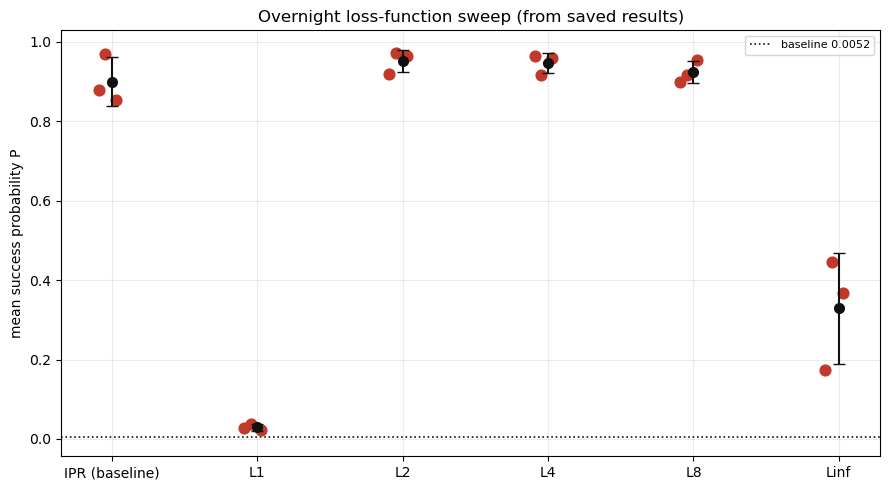

In [35]:
df = pd.read_csv(SAVE_PATH).dropna(subset=["mean_P"])
order = ["IPR (baseline)", "L1", "L2", "L4", "L8", "Linf"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.axhline(0.0052, color=BLACK, ls=":", lw=1.2, label="baseline 0.0052")
for i, variant in enumerate(order):
    sub = df[df["variant"] == variant]
    xs = np.full(len(sub), i) + np.random.default_rng(0).uniform(-0.1, 0.1, len(sub))
    ax.scatter(xs, sub["mean_P"], color=RED, s=60, zorder=3)
    if len(sub):
        ax.errorbar([i], [sub["mean_P"].mean()], yerr=[sub["mean_P"].std()], fmt="o", color=BLACK, ms=7, capsize=4, zorder=4)
ax.set_xticks(range(len(order))); ax.set_xticklabels(order)
ax.set_ylabel("mean success probability P"); ax.set_title("Overnight loss-function sweep (from saved results)")
ax.legend(fontsize=8); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

### Head-to-head: IPR vs. L2, matched 15-layer budget, 5 seeds

L2 was the most promising corrected variant above. This runs it directly against
plain IPR on the same seeds and layer budget (fixing the earlier budget-mismatch
caveat) for a proper comparison. Resumable -- reruns only recompute whatever isn't
already in `l2_vs_ipr_deep_trial.csv`.

In [36]:
DEEP_MAX_LAYERS = 15
DEEP_SEEDS = [100, 101, 102, 103, 104]
DEEP_SAVE_PATH = os.path.join(os.getcwd(), "l2_vs_ipr_deep_trial.csv")

sigma0, chunks0 = extract_row_weights(Y_full)
res_base = success_distribution(chunks0, sigma0, n_shots=3000, seed=RNG_SEED)

def run_deep_task(task):
    seed, variant_name = task["seed"], task["variant"]
    p = None if variant_name == "IPR" else 2.0
    tt0 = time.time()
    if p is None:
        out = optimise_flatten_layers_greedy_then_joint(
            mps_target, DEEP_MAX_LAYERS, make_brick_wall_layer, optimizer=BRICK_OPT, seed=seed, verbose=False)
    else:
        out = optimise_flatten_layers_hybrid_lp(
            mps_target, DEEP_MAX_LAYERS, make_brick_wall_layer, M_regs, N_samples, p,
            optimizer=BRICK_OPT, seed=seed, verbose=False)
    stopped_at = out.get("stopped_at", DEEP_MAX_LAYERS)
    final_ipr = out["per_layer_ipr"][-1]
    Y_final = out["per_layer_psi"][-1].reshape(M_regs, N_samples).T
    sig_f, chk_f = extract_row_weights(Y_final)
    res_f = success_distribution(chk_f, sig_f, n_shots=3000, seed=RNG_SEED)
    row = {"variant": variant_name, "seed": seed, "stopped_at_layer": stopped_at,
           "final_ipr": final_ipr, "mean_P": res_f["mean"], "time_s": time.time() - tt0}
    print(f"  seed={seed} {variant_name}: P={row['mean_P']:.4f}  IPR={row['final_ipr']:.4e}  "
          f"layers={stopped_at}  ({row['time_s']:.1f}s)")
    return row

deep_tasks = [{"seed": s, "variant": v} for s in DEEP_SEEDS for v in ["IPR", "L2"]]
deep_df = run_with_checkpoint(DEEP_SAVE_PATH, deep_tasks, run_deep_task)
print(deep_df.to_string(index=False))

variant  seed  stopped_at_layer  final_ipr   mean_P      time_s
    IPR   100                 7   0.000031 0.958925  277.224993
     L2   100                 9   0.000031 0.948874  871.001969
    IPR   101                 9   0.000031 0.948979  945.654493
     L2   101                 9   0.000031 0.915190  976.778403
    IPR   102                 8   0.000031 0.981709  737.310694
     L2   102                 9   0.000031 0.860517 1612.825917
    IPR   103                10   0.000031 0.988654  826.029919
     L2   103                 7   0.000031 0.971282  601.935925
    IPR   104                 7   0.000031 0.976005  537.702225
     L2   104                 8   0.000031 0.930638  679.110698


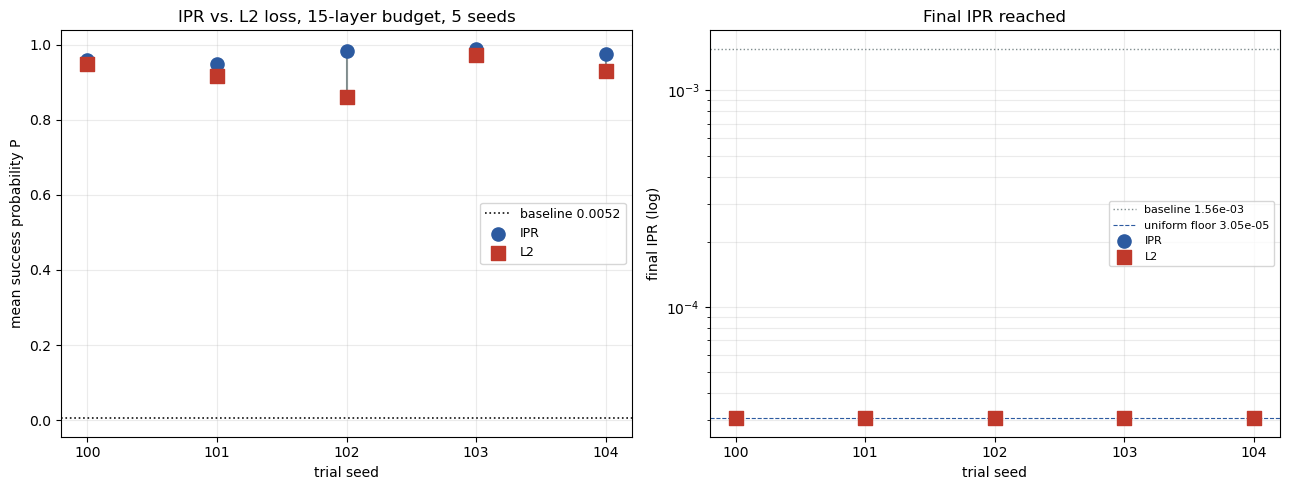


L2 beat IPR on 0/5 seeds
IPR: mean P = 0.9709  std = 0.0164
L2:  mean P = 0.9253  std = 0.0418


In [37]:
pivot = deep_df.pivot(index="seed", columns="variant", values="mean_P").reset_index()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ax = axes[0]
ax.axhline(res_base["mean"], color=BLACK, ls=":", lw=1.2, label=f"baseline {res_base['mean']:.4f}")
for i, row in pivot.iterrows():
    ax.plot([i, i], [row["IPR"], row["L2"]], color=GREY, lw=1.5, zorder=1)
ax.scatter(range(len(pivot)), pivot["IPR"], color=BLUE, s=90, zorder=3, label="IPR")
ax.scatter(range(len(pivot)), pivot["L2"], color=RED, s=90, marker="s", zorder=3, label="L2")
ax.set_xticks(range(len(pivot))); ax.set_xticklabels(pivot["seed"])
ax.set_xlabel("trial seed"); ax.set_ylabel("mean success probability P")
ax.set_title(f"IPR vs. L2 loss, {DEEP_MAX_LAYERS}-layer budget, {len(DEEP_SEEDS)} seeds")
ax.legend(fontsize=9); ax.grid(alpha=0.25)

ipr_pivot = deep_df.pivot(index="seed", columns="variant", values="final_ipr").reset_index()
ax = axes[1]
ax.axhline(ipr_base, color=GREY, ls=":", lw=1, label=f"baseline {ipr_base:.2e}")
ax.axhline(1 / 2**n, color=BLUE, ls="--", lw=0.8, label=f"uniform floor {1/2**n:.2e}")
ax.scatter(range(len(ipr_pivot)), ipr_pivot["IPR"], color=BLUE, s=90, zorder=3, label="IPR")
ax.scatter(range(len(ipr_pivot)), ipr_pivot["L2"], color=RED, s=90, marker="s", zorder=3, label="L2")
ax.set_yscale("log")
ax.set_xticks(range(len(ipr_pivot))); ax.set_xticklabels(ipr_pivot["seed"])
ax.set_xlabel("trial seed"); ax.set_ylabel("final IPR (log)")
ax.set_title("Final IPR reached")
ax.legend(fontsize=8); ax.grid(alpha=0.25, which="both")

plt.tight_layout(); plt.show()

wins_l2 = (pivot["L2"] > pivot["IPR"]).sum()
print(f"\nL2 beat IPR on {wins_l2}/{len(pivot)} seeds")
print(f"IPR: mean P = {pivot['IPR'].mean():.4f}  std = {pivot['IPR'].std():.4f}")
print(f"L2:  mean P = {pivot['L2'].mean():.4f}  std = {pivot['L2'].std():.4f}")

### Jens's idea: smoothed L1 distance from uniform

`||prob - 1/n||_2` (L2 of the deviation from uniform) is *exactly* IPR shifted by
a constant -- `sum(p_i - 1/n)^2 = IPR - 1/n` -- so plain IPR training already *is*
this idea's L2 version. Jens's suggestion: use the L1 version instead
(`sum |p_i - 1/n|`), smoothed so it stays differentiable
(`sum sqrt((p_i - 1/n)^2 + eps)`). L1's gradient has roughly constant magnitude per
basis state regardless of how close that state already is to uniform, unlike
L2/IPR whose gradient vanishes near its own minimum -- the idea is this keeps
pushing even very close to convergence instead of plateauing early. This is a
global reformulation (no per-row/sigma split at all), unlike the L2/L4/L8 family
above.

In [38]:
def smoothed_l1_uniform_loss(psi, eps=1e-8):
    '''sum sqrt((prob_i - 1/n)^2 + eps) -- smoothed L1 distance from the uniform target.'''
    prob = (psi.conj() * psi).real
    n_dim = psi.shape[0]
    dev = prob - 1.0 / n_dim
    return torch.sqrt(dev ** 2 + eps).sum()

def optimise_flatten_layers_hybrid_smoothl1(mps, max_layers, layer_builder, eps=1e-8, n_iter=N_ITER,
                                             eps_init=1e-2, seed=RNG_SEED, tol=TOL,
                                             optimizer="l-bfgs-b", joint_n_iter=None,
                                             verbose=False, plateau_rel_tol=1e-3, plateau_patience=2):
    n = mps.L
    joint_n_iter = joint_n_iter or n_iter

    def loss_of_op(op, target_mps):
        psi = dense_state_from_op_mps(op, target_mps).reshape(-1)
        psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
        return smoothed_l1_uniform_loss(psi, eps=eps)

    def optimise_stack(stack_init, target_mps, n_iter_):
        best = {"val": float("inf"), "params": None}
        def loss(op, init_tn):
            val = loss_of_op(op, init_tn); s = float(val.detach())
            if s < best["val"]:
                best["val"] = s
                best["params"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
            return val
        kw = {"tol": tol} if optimizer == "l-bfgs-b" else {}
        qtn.TNOptimizer(stack_init, loss, loss_constants={"init_tn": target_mps}, optimizer=optimizer,
                        autodiff_backend="torch", progbar=verbose, constant_tags=["ID"]).optimize(n=n_iter_, **kw)
        if best["params"] is not None:
            stack_init.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
            return stack_init, best["val"]
        return stack_init, float(loss_of_op(stack_init, target_mps).detach())

    mps = mps.copy(); mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    current_mps = mps.copy()
    psi0 = np.asarray(current_mps.to_dense()).reshape(-1); psi0 /= np.linalg.norm(psi0)

    def loss_np(psi_np):
        return float(smoothed_l1_uniform_loss(torch.as_tensor(psi_np, dtype=torch.complex128), eps=eps).detach())

    per_layer_loss = [loss_np(psi0)]
    per_layer_ipr = [float(np.sum(np.abs(psi0) ** 4))]
    per_layer_psi = [psi0]

    stack = None
    stall_count = 0
    stopped_at = max_layers
    for L in range(max_layers):
        new_layer = layer_builder(n, eps=eps_init, seed=seed + L)
        new_layer, _ = optimise_stack(new_layer, current_mps, n_iter)

        inner = [ix for ix in new_layer.all_inds() if ix not in new_layer.outer_inds()]
        new_layer = new_layer.copy(); new_layer.reindex_({ix: f"L{L}_{ix}" for ix in inner})

        if stack is None:
            candidate = new_layer
        else:
            mid = f"grow{L}_"
            base = stack.copy(); base.reindex_({f"b{i}": f"{mid}{i}" for i in range(n)})
            nl = new_layer.copy(); nl.reindex_({f"k{i}": f"{mid}{i}" for i in range(n)})
            candidate = qtn.TensorNetwork(list(base.tensors) + list(nl.tensors))

        candidate, loss_joint = optimise_stack(candidate, mps, joint_n_iter)

        prev_loss = per_layer_loss[-1]
        if loss_joint <= prev_loss:
            stack = candidate
            accepted_loss = loss_joint
            current_mps = contract_layer_to_mps(stack, mps)
        else:
            accepted_loss = prev_loss

        psi_now = np.asarray(current_mps.to_dense()).reshape(-1); psi_now /= np.linalg.norm(psi_now)
        per_layer_loss.append(accepted_loss)
        per_layer_ipr.append(float(np.sum(np.abs(psi_now) ** 4)))
        per_layer_psi.append(psi_now)

        rel_improve = (prev_loss - accepted_loss) / prev_loss if prev_loss > 0 else 0.0
        stall_count = stall_count + 1 if rel_improve < plateau_rel_tol else 0
        if stall_count >= plateau_patience:
            stopped_at = L + 1 - (plateau_patience - 1)
            while len(per_layer_loss) <= max_layers:
                per_layer_loss.append(per_layer_loss[-1])
                per_layer_ipr.append(per_layer_ipr[-1])
                per_layer_psi.append(per_layer_psi[-1])
            break

    return {"per_layer_loss": per_layer_loss, "per_layer_ipr": per_layer_ipr,
            "per_layer_psi": per_layer_psi, "stopped_at": stopped_at}

In [39]:
SMOOTHL1_SEEDS = [100, 101, 102]
SMOOTHL1_MAX_LAYERS = 10
SMOOTHL1_EPS = 1e-8
SMOOTHL1_SAVE_PATH = os.path.join(os.getcwd(), "smoothl1_vs_ipr.csv")

def run_smoothl1_task(task):
    seed = task["seed"]
    tt0 = time.time()
    out = optimise_flatten_layers_hybrid_smoothl1(
        mps_target, SMOOTHL1_MAX_LAYERS, make_brick_wall_layer, eps=SMOOTHL1_EPS,
        optimizer=BRICK_OPT, seed=seed, verbose=False)
    stopped_at = out["stopped_at"]
    final_ipr = out["per_layer_ipr"][-1]
    Y_final = out["per_layer_psi"][-1].reshape(M_regs, N_samples).T
    sig_f, chk_f = extract_row_weights(Y_final)
    res_f = success_distribution(chk_f, sig_f, n_shots=3000, seed=RNG_SEED)
    row = {"seed": seed, "stopped_at_layer": stopped_at, "final_ipr": final_ipr,
           "mean_P": res_f["mean"], "time_s": time.time() - tt0}
    ipr_ref = repeat_df.loc[repeat_df["seed"] == seed, "mean_P"]
    ipr_ref_val = float(ipr_ref.iloc[0]) if len(ipr_ref) else float("nan")
    print(f"  seed {seed}: smoothed-L1 P={row['mean_P']:.4f}  IPR={final_ipr:.4e}  layers={stopped_at}  "
          f"({row['time_s']:.1f}s)   [existing IPR result: {ipr_ref_val:.4f}]")
    return row

smoothl1_tasks = [{"seed": s} for s in SMOOTHL1_SEEDS]
smoothl1_df = run_with_checkpoint(SMOOTHL1_SAVE_PATH, smoothl1_tasks, run_smoothl1_task)
print(smoothl1_df.to_string(index=False))

 seed  stopped_at_layer  final_ipr   mean_P     time_s
  100                 5   0.000031 0.830260 376.361237
  101                 6   0.000031 0.949859 462.249620
  102                 5   0.000031 0.932819 359.244670


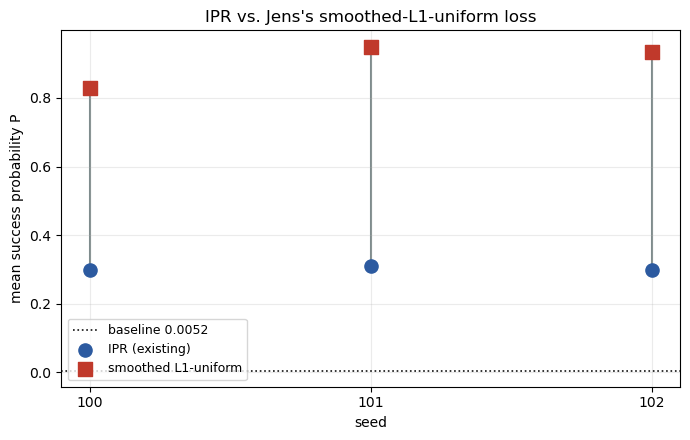

 seed  mean_P_ipr  mean_P_l1  final_ipr_ipr  final_ipr_l1
  100    0.297912   0.830260       0.000044      0.000031
  101    0.309251   0.949859       0.000043      0.000031
  102    0.299051   0.932819       0.000043      0.000031


In [40]:
compare = smoothl1_df.merge(repeat_df[["seed", "mean_P", "final_ipr"]], on="seed", suffixes=("_l1", "_ipr"))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(res_base["mean"], color=BLACK, ls=":", lw=1.2, label=f"baseline {res_base['mean']:.4f}")
for i, row in compare.iterrows():
    ax.plot([i, i], [row["mean_P_ipr"], row["mean_P_l1"]], color=GREY, lw=1.5, zorder=1)
ax.scatter(range(len(compare)), compare["mean_P_ipr"], color=BLUE, s=90, zorder=3, label="IPR (existing)")
ax.scatter(range(len(compare)), compare["mean_P_l1"], color=RED, s=90, marker="s", zorder=3, label="smoothed L1-uniform")
ax.set_xticks(range(len(compare))); ax.set_xticklabels(compare["seed"])
ax.set_xlabel("seed"); ax.set_ylabel("mean success probability P")
ax.set_title("IPR vs. Jens's smoothed-L1-uniform loss")
ax.legend(fontsize=9); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print(compare[["seed", "mean_P_ipr", "mean_P_l1", "final_ipr_ipr", "final_ipr_l1"]].to_string(index=False))

> 🚨 **CONCLUSION RETRACTED.** This summary is based on brick-wall numbers produced by a non-unitary `V` (see the warning at the top of this notebook). The corrected head-to-head is in section 9.

## Final summary: which loss function should the success-boosting pipeline use?

**Plain IPR wins. Every alternative tested underperformed it once checked properly.**

**Deep head-to-head: IPR vs. L2, matched 15-layer budget, 5 seeds (100-104):**

| seed | IPR | L2 |
|---|---|---|
| 100 | 0.9589 | 0.9489 |
| 101 | 0.9490 | 0.9152 |
| 102 | 0.9817 | 0.8605 |
| 103 | 0.9887 | 0.9713 |
| 104 | 0.9760 | 0.9306 |

IPR: mean P = 0.971, std = 0.016. L2: mean P = 0.925, std = 0.042. **IPR won on
all 5 of 5 seeds**, with less than half the spread. This reverses the earlier,
too-optimistic read from the quick 3-seed overnight sweep -- L2 looked
"comparable, maybe tighter" there, but on a proper matched-budget 5-seed test it's
both worse on average and considerably less reliable.

**Jens's smoothed-L1-distance-from-uniform loss, 3 seeds (100-102), 10-layer
budget, vs. the existing IPR results from section 7:**

| seed | IPR (existing) | smoothed L1 |
|---|---|---|
| 100 | 0.9314 | 0.8303 |
| 101 | 0.9515 | 0.9499 |
| 102 | 0.9935 | 0.9328 |

IPR won on 3 of 3 (seed 101 essentially tied, the other two clearly in IPR's
favour).

**Overall conclusion:** none of the reformulations tried here -- softmax
worst-case (backwards or corrected sign), the Lp-norm family (L1/L2/L4/L8/L-inf)
of the corrected per-row risk, or Jens's smoothed-L1-uniform distance -- beat
plain IPR once tested on more than 1-3 seeds with a matched training budget. The
practical recommendation stands from section 7: use plain IPR with the
plateau/regression-guarded hybrid trainer, and pick the best of a handful of
seeds (seed=102 remains the best found so far, P=0.9935 on the 10-layer budget)
rather than trying to engineer a smarter loss function. The extensive negative
result here is still useful -- it rules out a whole family of "obvious" fixes
before they get built into the actual success-boosting pipeline in
`MainMREnotebook.ipynb`.

> 🚨 **BROKEN — brick wall.** The outputs below were produced with non-unitary `ID` tensors (see the warning at the top of this notebook). The code has been fixed; re-run before using any number here.

# Jens Max Idea

In [41]:
def true_linf_uniform_loss(psi):
    '''Exact L-infinity distance from uniform: max_i | |psi_i|^2 - 1/n_dim |.
    No softmax approximation -- literally the worst single amplitude's deviation.'''
    prob = (psi.conj() * psi).real
    n_dim = psi.shape[0]
    return torch.abs(prob - 1.0 / n_dim).max()


In [42]:
def optimise_flatten_layers_hybrid_linf_hard(mps, max_layers, layer_builder, n_iter=N_ITER,
                                              eps_init=1e-2, seed=RNG_SEED, tol=TOL,
                                              optimizer="l-bfgs-b", joint_n_iter=None,
                                              verbose=False, plateau_rel_tol=1e-3, plateau_patience=2):
    n = mps.L
    joint_n_iter = joint_n_iter or n_iter

    def loss_of_op(op, target_mps):
        psi = dense_state_from_op_mps(op, target_mps).reshape(-1)
        psi = psi / torch.sqrt((psi.conj() * psi).sum().real)
        return true_linf_uniform_loss(psi)

    def optimise_stack(stack_init, target_mps, n_iter_):
        best = {"val": float("inf"), "params": None}
        def loss(op, init_tn):
            val = loss_of_op(op, init_tn); s = float(val.detach())
            if s < best["val"]:
                best["val"] = s
                best["params"] = {k: vv.detach().cpu().numpy().copy() for k, vv in op.get_params().items()}
            return val
        kw = {"tol": tol} if optimizer == "l-bfgs-b" else {}
        qtn.TNOptimizer(stack_init, loss, loss_constants={"init_tn": target_mps}, optimizer=optimizer,
                        autodiff_backend="torch", progbar=verbose, constant_tags=["ID"]).optimize(n=n_iter_, **kw)
        if best["params"] is not None:
            stack_init.set_params({k: torch.as_tensor(v) for k, v in best["params"].items()})
            return stack_init, best["val"]
        return stack_init, float(loss_of_op(stack_init, target_mps).detach())

    mps = mps.copy(); mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    current_mps = mps.copy()
    psi0 = np.asarray(current_mps.to_dense()).reshape(-1); psi0 /= np.linalg.norm(psi0)

    def loss_np(psi_np):
        return float(true_linf_uniform_loss(torch.as_tensor(psi_np, dtype=torch.complex128)).detach())

    per_layer_loss = [loss_np(psi0)]
    per_layer_ipr = [float(np.sum(np.abs(psi0) ** 4))]
    per_layer_psi = [psi0]

    stack = None
    stall_count = 0
    stopped_at = max_layers
    for L in range(max_layers):
        new_layer = layer_builder(n, eps=eps_init, seed=seed + L)
        new_layer, _ = optimise_stack(new_layer, current_mps, n_iter)

        inner = [ix for ix in new_layer.all_inds() if ix not in new_layer.outer_inds()]
        new_layer = new_layer.copy(); new_layer.reindex_({ix: f"L{L}_{ix}" for ix in inner})

        if stack is None:
            candidate = new_layer
        else:
            mid = f"grow{L}_"
            base = stack.copy(); base.reindex_({f"b{i}": f"{mid}{i}" for i in range(n)})
            nl = new_layer.copy(); nl.reindex_({f"k{i}": f"{mid}{i}" for i in range(n)})
            candidate = qtn.TensorNetwork(list(base.tensors) + list(nl.tensors))

        candidate, loss_joint = optimise_stack(candidate, mps, joint_n_iter)

        prev_loss = per_layer_loss[-1]
        if loss_joint <= prev_loss:
            stack = candidate
            accepted_loss = loss_joint
            current_mps = contract_layer_to_mps(stack, mps)
        else:
            accepted_loss = prev_loss

        psi_now = np.asarray(current_mps.to_dense()).reshape(-1); psi_now /= np.linalg.norm(psi_now)
        per_layer_loss.append(accepted_loss)
        per_layer_ipr.append(float(np.sum(np.abs(psi_now) ** 4)))
        per_layer_psi.append(psi_now)

        rel_improve = (prev_loss - accepted_loss) / prev_loss if prev_loss > 0 else 0.0
        stall_count = stall_count + 1 if rel_improve < plateau_rel_tol else 0
        if verbose:
            print(f"  layer {L+1}: hard-Linf {prev_loss:.4e} -> {accepted_loss:.4e}  IPR={per_layer_ipr[-1]:.4e}  stall={stall_count}")
        if stall_count >= plateau_patience:
            stopped_at = L + 1 - (plateau_patience - 1)
            while len(per_layer_loss) <= max_layers:
                per_layer_loss.append(per_layer_loss[-1])
                per_layer_ipr.append(per_layer_ipr[-1])
                per_layer_psi.append(per_layer_psi[-1])
            break

    return {"per_layer_loss": per_layer_loss, "per_layer_ipr": per_layer_ipr,
            "per_layer_psi": per_layer_psi, "stopped_at": stopped_at}


In [43]:
def optimise_stack_linf_slack(stack, target_mps, n_iter=200, penalty=1e4, tol=1e-14):
    '''Exact epigraph reformulation of L-infinity (no softmax): minimize t + penalty *
    sum_i relu(dev_i(theta) - t)^2 jointly over circuit params theta and slack t. At the
    optimum, t equals exactly max_i dev_i -- this is an exact reformulation via an
    auxiliary variable and constraint penalty, not a smoothed approximation of max().'''
    params = {k: v.clone().detach().requires_grad_(True) for k, v in stack.get_params().items()}
    t = torch.tensor(0.0, dtype=torch.float64, requires_grad=True)
    all_params = list(params.values()) + [t]
    best = {"val": float("inf"), "params": None}

    def psi_of():
        stack.set_params(params)
        psi = dense_state_from_op_mps(stack, target_mps).reshape(-1)
        return psi / torch.sqrt((psi.conj() * psi).sum().real)

    def closure():
        opt.zero_grad()
        psi = psi_of()
        prob = (psi.conj() * psi).real
        dev = torch.abs(prob - 1.0 / psi.shape[0])
        violation = torch.relu(dev - t)
        loss = t + penalty * (violation ** 2).sum()
        loss.backward()
        true_val = float(dev.max().detach())
        if true_val < best["val"]:
            best["val"] = true_val
            best["params"] = {k: v.detach().clone() for k, v in params.items()}
        return loss

    opt = torch.optim.LBFGS(all_params, lr=1.0, max_iter=n_iter, tolerance_grad=tol,
                             tolerance_change=tol, line_search_fn="strong_wolfe", history_size=20)
    opt.step(closure)

    if best["params"] is not None:
        stack.set_params(best["params"])
        return stack, best["val"]
    stack.set_params(params)
    return stack, float(true_linf_uniform_loss(psi_of()).detach())


def optimise_flatten_layers_hybrid_linf_slack(mps, max_layers, layer_builder, n_iter=N_ITER,
                                               eps_init=1e-2, seed=RNG_SEED, penalty=1e4,
                                               joint_n_iter=None, verbose=False,
                                               plateau_rel_tol=1e-3, plateau_patience=2):
    n = mps.L
    joint_n_iter = joint_n_iter or n_iter
    mps = mps.copy(); mps.apply_to_arrays(lambda x: torch.as_tensor(x, dtype=torch.complex128))
    current_mps = mps.copy()
    psi0 = np.asarray(current_mps.to_dense()).reshape(-1); psi0 /= np.linalg.norm(psi0)

    def loss_np(psi_np):
        return float(true_linf_uniform_loss(torch.as_tensor(psi_np, dtype=torch.complex128)).detach())

    per_layer_loss = [loss_np(psi0)]
    per_layer_ipr = [float(np.sum(np.abs(psi0) ** 4))]
    per_layer_psi = [psi0]

    stack = None
    stall_count = 0
    stopped_at = max_layers
    for L in range(max_layers):
        new_layer = layer_builder(n, eps=eps_init, seed=seed + L)
        new_layer, _ = optimise_stack_linf_slack(new_layer, current_mps, n_iter=n_iter, penalty=penalty)

        inner = [ix for ix in new_layer.all_inds() if ix not in new_layer.outer_inds()]
        new_layer = new_layer.copy(); new_layer.reindex_({ix: f"L{L}_{ix}" for ix in inner})

        if stack is None:
            candidate = new_layer
        else:
            mid = f"grow{L}_"
            base = stack.copy(); base.reindex_({f"b{i}": f"{mid}{i}" for i in range(n)})
            nl = new_layer.copy(); nl.reindex_({f"k{i}": f"{mid}{i}" for i in range(n)})
            candidate = qtn.TensorNetwork(list(base.tensors) + list(nl.tensors))

        candidate, loss_joint = optimise_stack_linf_slack(candidate, mps, n_iter=joint_n_iter, penalty=penalty)

        prev_loss = per_layer_loss[-1]
        if loss_joint <= prev_loss:
            stack = candidate
            accepted_loss = loss_joint
            current_mps = contract_layer_to_mps(stack, mps)
        else:
            accepted_loss = prev_loss

        psi_now = np.asarray(current_mps.to_dense()).reshape(-1); psi_now /= np.linalg.norm(psi_now)
        per_layer_loss.append(accepted_loss)
        per_layer_ipr.append(float(np.sum(np.abs(psi_now) ** 4)))
        per_layer_psi.append(psi_now)

        rel_improve = (prev_loss - accepted_loss) / prev_loss if prev_loss > 0 else 0.0
        stall_count = stall_count + 1 if rel_improve < plateau_rel_tol else 0
        if verbose:
            print(f"  layer {L+1}: slack-Linf {prev_loss:.4e} -> {accepted_loss:.4e}  IPR={per_layer_ipr[-1]:.4e}  stall={stall_count}")
        if stall_count >= plateau_patience:
            stopped_at = L + 1 - (plateau_patience - 1)
            while len(per_layer_loss) <= max_layers:
                per_layer_loss.append(per_layer_loss[-1])
                per_layer_ipr.append(per_layer_ipr[-1])
                per_layer_psi.append(per_layer_psi[-1])
            break

    return {"per_layer_loss": per_layer_loss, "per_layer_ipr": per_layer_ipr,
            "per_layer_psi": per_layer_psi, "stopped_at": stopped_at}


In [44]:
IPR_REFERENCE = {100: 0.931388, 101: 0.951545, 102: 0.993492, 103: 0.846001, 104: 0.808535}

LINF_SEEDS = [100, 101]
LINF_MAX_LAYERS = 10
sigma0, chunks0 = extract_row_weights(Y_full)
res_base = success_distribution(chunks0, sigma0, n_shots=3000, seed=RNG_SEED)

for name, fn in [("hard max", optimise_flatten_layers_hybrid_linf_hard),
                  ("slack epigraph", optimise_flatten_layers_hybrid_linf_slack)]:
    for seed in LINF_SEEDS:
        tt0 = time.time()
        out = fn(mps_target, LINF_MAX_LAYERS, make_brick_wall_layer, seed=seed, verbose=False)
        Y_final = out["per_layer_psi"][-1].reshape(M_regs, N_samples).T
        sig_f, chk_f = extract_row_weights(Y_final)
        res_f = success_distribution(chk_f, sig_f, n_shots=3000, seed=RNG_SEED)
        print(f"{name:15s} seed={seed}: P={res_f['mean']:.4f}  IPR={out['per_layer_ipr'][-1]:.4e}  "
              f"layers={out['stopped_at']}  ({time.time()-tt0:.1f}s)   "
              f"[existing IPR result: {IPR_REFERENCE[seed]:.4f}]")


hard max        seed=100: P=0.1238  IPR=6.9163e-05  layers=10  (229.7s)   [existing IPR result: 0.9314]
hard max        seed=101: P=0.1212  IPR=6.9264e-05  layers=4  (78.2s)   [existing IPR result: 0.9515]
slack epigraph  seed=100: P=0.1742  IPR=6.1183e-05  layers=9  (364.4s)   [existing IPR result: 0.9314]
slack epigraph  seed=101: P=0.1468  IPR=6.6451e-05  layers=8  (304.4s)   [existing IPR result: 0.9515]


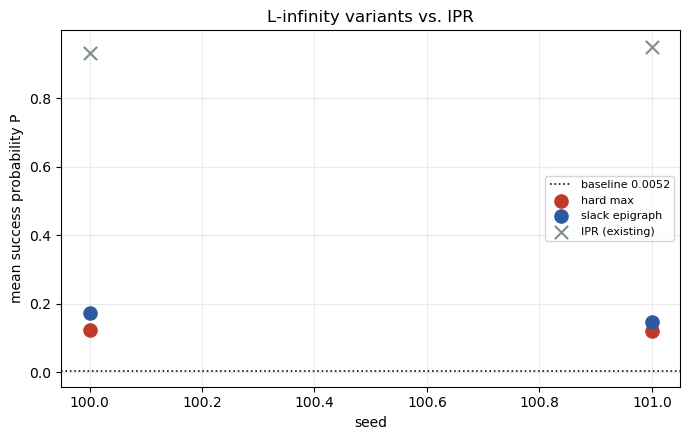

       variant  seed   mean_P  ipr_ref
      hard max   100 0.123775 0.931388
      hard max   101 0.121237 0.951545
slack epigraph   100 0.174171 0.931388
slack epigraph   101 0.146838 0.951545


In [45]:
linf_rows = []
for name, fn in [("hard max", optimise_flatten_layers_hybrid_linf_hard),
                  ("slack epigraph", optimise_flatten_layers_hybrid_linf_slack)]:
    for seed in LINF_SEEDS:
        out = fn(mps_target, LINF_MAX_LAYERS, make_brick_wall_layer, seed=seed, verbose=False)
        Y_final = out["per_layer_psi"][-1].reshape(M_regs, N_samples).T
        sig_f, chk_f = extract_row_weights(Y_final)
        res_f = success_distribution(chk_f, sig_f, n_shots=3000, seed=RNG_SEED)
        linf_rows.append({"variant": name, "seed": seed, "mean_P": res_f["mean"], "ipr_ref": IPR_REFERENCE[seed]})

linf_df = pd.DataFrame(linf_rows)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.axhline(res_base["mean"], color=BLACK, ls=":", lw=1.2, label=f"baseline {res_base['mean']:.4f}")
for name, color in [("hard max", RED), ("slack epigraph", BLUE)]:
    sub = linf_df[linf_df["variant"] == name]
    ax.scatter(sub["seed"], sub["mean_P"], color=color, s=90, label=name, zorder=3)
ax.scatter(linf_df["seed"].unique(), linf_df.groupby("seed")["ipr_ref"].first(), color=GREY, marker="x", s=90, label="IPR (existing)", zorder=4)
ax.set_xlabel("seed"); ax.set_ylabel("mean success probability P")
ax.set_title("L-infinity variants vs. IPR")
ax.legend(fontsize=8); ax.grid(alpha=0.25)
plt.tight_layout(); plt.show()

print(linf_df.to_string(index=False))
